# Late orders on Olist


In [1]:
import json, urllib.request
from datetime import datetime, timedelta
from pathlib import Path
import kagglehub, polars as pl, matplotlib.pyplot as plt, numpy as np
import matplotlib.patheffects as pe

BLUE, ORANGE, RED, GREY = "#2a78d6", "#eb6834", "#e34948", "#898781"
MONTH_TICKS = [datetime(2017, 1, 1), datetime(2017, 7, 1), datetime(2018, 1, 1), datetime(2018, 7, 1)], ["Jan 17", "Jul 17", "Jan 18", "Jul 18"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e1e0d9", "grid.linewidth": .6, "axes.axisbelow": True})
pl.Config.set_fmt_str_lengths(120); pl.Config.set_tbl_width_chars(220);

## 1 · Importing and cleaning the data
 
Olist is a Brazilian marketplace that lets small sellers list their products on large online stores. The data covers 99k orders that 96k customers placed with 3.1k sellers between September 2016 and Aug 2018. It includes geo information about customers and sellers, promised date of delivery versus actual date of delivery, order rating as well as optional text review and more. The raw tables come from Kaggle (`olistbr/brazilian-ecommerce`). 

### Raw tables

In [2]:
data_dir = Path("data")
raw_data_dir = data_dir / "raw"
raw = Path(kagglehub.dataset_download("olistbr/brazilian-ecommerce", output_dir=raw_data_dir))
read = lambda name: pl.read_csv(raw / f"olist_{name}_dataset.csv", try_parse_dates=True)

table_names = [
    "orders", "order_items", "order_payments",
    "order_reviews", "customers", "sellers",
    "products", "geolocation",
]

tables = {f"otab_{name}": read(name) for name in table_names}
tables["otab_category_translation"] = pl.read_csv(
    raw / "product_category_name_translation.csv" # only table that doesn't follow the olist_{name}_dataset.csv naming pattern in the source
)
tables["otab_orders"].head()

order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
str,str,str,datetime[μs],datetime[μs],datetime[μs],datetime[μs],datetime[μs]
"""e481f51cbdc54678b7cc49136f2d6af7""","""9ef432eb6251297304e76186b10a928d""","""delivered""",2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
"""53cdb2fc8bc7dce0b6741e2150273451""","""b0830fb4747a6c6d20dea0b8c802d7ef""","""delivered""",2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
"""47770eb9100c2d0c44946d9cf07ec65d""","""41ce2a54c0b03bf3443c3d931a367089""","""delivered""",2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
"""949d5b44dbf5de918fe9c16f97b45f8a""","""f88197465ea7920adcdbec7375364d82""","""delivered""",2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
"""ad21c59c0840e6cb83a9ceb5573f8159""","""8ab97904e6daea8866dbdbc4fb7aad2c""","""delivered""",2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [3]:
HOLDS = {
    "otab_orders": "one per order: status and timestamps (purchase, approval, handed to carrier, delivered, promised date)",
    "otab_order_items": "one per item: seller, product, price and delivery fee",
    "otab_order_payments": "one per payment: type, instalments, amount",
    "otab_order_reviews": "one per review: 1–5 stars and optional comment",
    "otab_customers": "one per order's customer: city, state, zip prefix; customer_unique_id identifies the person",
    "otab_sellers": "one per seller: city, state, zip prefix",
    "otab_products": "one per product: category, size, weight",
    "otab_geolocation": "lat/long points per zip prefix",
    "otab_category_translation": "Portuguese → English category names",
}
pl.DataFrame({
    "table": list(HOLDS),
    "rows": [tables[name].height for name in HOLDS],
    "columns": [tables[name].width for name in HOLDS],
    "holds": list(HOLDS.values()),
})

table,rows,columns,holds
str,i64,i64,str
"""otab_orders""",99441,8,"""one per order: status and timestamps (purchase, approval, handed to carrier, delivered, promised date)"""
"""otab_order_items""",112650,7,"""one per item: seller, product, price and delivery fee"""
"""otab_order_payments""",103886,5,"""one per payment: type, instalments, amount"""
"""otab_order_reviews""",99224,7,"""one per review: 1–5 stars and optional comment"""
"""otab_customers""",99441,5,"""one per order's customer: city, state, zip prefix; customer_unique_id identifies the person"""
"""otab_sellers""",3095,4,"""one per seller: city, state, zip prefix"""
"""otab_products""",32951,9,"""one per product: category, size, weight"""
"""otab_geolocation""",1000163,5,"""lat/long points per zip prefix"""
"""otab_category_translation""",71,2,"""Portuguese → English category names"""


### Period kept

Sep–Dec 2016 and Sep–Oct 2018 have only a few hundred orders between them (the platform was ramping up, and the extract ends in Aug 2018), so I keep orders placed Jan 2017 – Aug 2018.

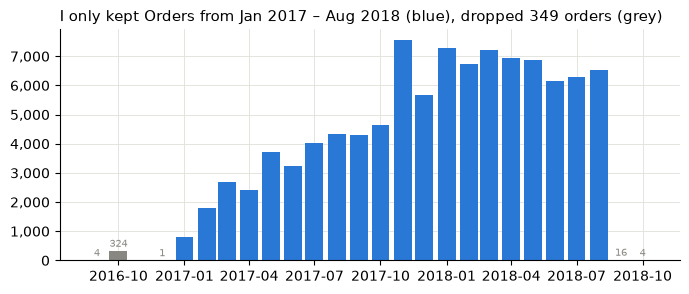

In [4]:
df_monthly = (
    tables["otab_orders"].group_by(month=pl.col("order_purchase_timestamp").dt.truncate("1mo"))
    .agg(n=pl.len()).sort("month")
    .with_columns(kept=pl.col("month").is_between(datetime(2017, 1, 1), datetime(2018, 9, 1), closed="left"))
    )
dropped = df_monthly.filter(~pl.col("kept"))["n"].sum()

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(df_monthly["month"].to_list(), df_monthly["n"], width=25, color=[BLUE if k else GREY for k in df_monthly["kept"]])
for r in df_monthly.filter(~pl.col("kept")).iter_rows(named=True):   # label the dropped months
    ax.annotate(f"{r['n']:,}", (r["month"], r["n"]), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=7, color=GREY)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.set_title(f"I only kept Orders from Jan 2017 – Aug 2018 (blue), dropped {dropped:,} orders (grey)", loc="left", fontsize=11);


### Working tables: items and orders

Two tables, at two levels of detail:

- `df_items`: one row per item sold. An order can contain several items, possibly from different sellers. Seller, category, price and delivery fee all live here.
- `df_orders`: one row per order, with its status, dates, customer and the order features below. Its price columns are its items added up (`df_order_totals`): `price_excl_delivery` is the sum of item prices, `delivery_fee` is the sum of item delivery fees, and `price_incl_delivery` is both together.

Lateness is an order-level event (one promised date, one delivery date), so the late-order analysis uses `df_orders`. Questions about who sells what use `df_items`.

#### Items table

In [5]:
in_period = pl.col("order_purchase_timestamp").is_between(datetime(2017, 1, 1), datetime(2018, 9, 1), closed="left")
df_orders_kept = tables["otab_orders"].filter(in_period)

# one row per item sold
df_items = (tables["otab_order_items"]
    .join(df_orders_kept.select("order_id", "customer_id", "order_purchase_timestamp"), on="order_id")   # inner: drops items of orders outside the period
    .join(tables["otab_customers"].select("customer_id", "customer_state"), on="customer_id")
    .join(tables["otab_sellers"].select("seller_id", "seller_state"), on="seller_id")
    .join(tables["otab_products"].select("product_id", "product_category_name"), on="product_id", how="left")
    .join(tables["otab_category_translation"], on="product_category_name", how="left")
    .with_columns(category=pl.coalesce("product_category_name_english", "product_category_name", pl.lit("missing_category")))   # English, else Portuguese, else missing
    .rename({"price": "price_excl_delivery", "freight_value": "delivery_fee"}))

# items aggregated to one row per order
df_order_totals = df_items.group_by("order_id").agg(
    n_items=pl.len(), n_sellers=pl.col("seller_id").n_unique(),   # one order can have several sellers (~1k orders)
    price_excl_delivery=pl.sum("price_excl_delivery"), delivery_fee=pl.sum("delivery_fee"))


#### Order features

Everything the late-order analysis needs about an order is built once here and added to `df_orders`. Choices made along the way:

- **Locations:** a zip prefix covers many geolocation points, so each prefix gets the median latitude and longitude of its points. Zip prefixes with no points get no location.
- **Distance:** the straight-line (great-circle) distance from seller to customer, not the road distance. When an order has several sellers, the farthest one is used.
- **Weight:** the sum of the order's product weights, counting each item row, since quantity is stored as repeated rows. A product with no recorded weight counts as 0.
- **Shipping deadline (`shipping_limit`):** each item has its own deadline for the seller to hand it to the carrier; the order takes the latest.
- **In-state:** true only when every seller in the order is in the customer's state.
- **Main seller:** the seller of the order's first item. For the 1.3% of orders with several sellers, this choice is arbitrary.
- **Boleto:** true when any payment on the order is a boleto, even when cards cover most of the amount.
- **Region:** the customer's region, one of Brazil's five official groupings of states.
- **Promised days:** from purchase to the promised delivery date. That date has no time, so it counts from midnight.
- **Hours to approval:** from purchase to payment approval. It is missing for orders never approved.
- **Orders without items** (739, never shipped) get no item-based features.

In [6]:
REGION = {**dict.fromkeys(["AC", "AP", "AM", "PA", "RO", "RR", "TO"], "North"),
          **dict.fromkeys(["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"], "North-East"),
          **dict.fromkeys(["DF", "GO", "MT", "MS"], "Centre-West"),
          **dict.fromkeys(["ES", "MG", "RJ", "SP"], "South-East"),
          **dict.fromkeys(["PR", "RS", "SC"], "South")}

# one point per zip prefix: the median of its geolocation points
df_zip_xy = (tables["otab_geolocation"].group_by(zip_code_prefix="geolocation_zip_code_prefix")   # median lat/lng per zip prefix, to avoid outliers
    .agg(lat=pl.median("geolocation_lat"), lng=pl.median("geolocation_lng")))
df_customer_xy = (tables["otab_customers"].join(df_zip_xy, left_on="customer_zip_code_prefix", right_on="zip_code_prefix", how="left")
    .select("customer_id", "lat", "lng"))
df_seller_xy = (tables["otab_sellers"].join(df_zip_xy, left_on="seller_zip_code_prefix", right_on="zip_code_prefix", how="left")
    .select("seller_id", seller_lat="lat", seller_lng="lng"))

def km(lat1, lng1, lat2, lng2):
    "Great-circle distance in km between two points given as column names."
    lat1, lng1, lat2, lng2 = (pl.col(c).radians() for c in (lat1, lng1, lat2, lng2))
    a = ((lat2 - lat1) / 2).sin() ** 2 + lat1.cos() * lat2.cos() * ((lng2 - lng1) / 2).sin() ** 2
    return 2 * 6371 * a.sqrt().arcsin()

# item-based features, one row per order
df_order_features = (df_items
    .join(tables["otab_products"].select("product_id", "product_weight_g"), on="product_id", how="left")
    .join(df_seller_xy, on="seller_id").join(df_customer_xy, on="customer_id")
    .group_by("order_id").agg(
        main_seller=pl.col("seller_id").sort_by("order_item_id").first(),   # seller of the first item
        in_state=(pl.col("seller_state") == pl.col("customer_state")).all(),   # every seller in the customer's state
        weight_kg=pl.sum("product_weight_g") / 1000,   # missing weights count as 0 - only 16 orders
        distance_km=km("seller_lat", "seller_lng", "lat", "lng").max(),   # farthest seller (~1k orders with multiple sellers)
        shipping_limit=pl.max("shipping_limit_date")))   # latest deadline to hand the order to the carrier
df_boleto = tables["otab_order_payments"].group_by("order_id").agg(boleto=(pl.col("payment_type") == "boleto").any())

In [7]:
# one row per order
df_orders = (df_orders_kept
    .join(tables["otab_customers"], on="customer_id")
    .join(df_order_totals, on="order_id", how="left")   # left: keeps orders that have no items
    .join(df_order_features, on="order_id", how="left")   # left: orders without items get no features
    .join(df_boleto, on="order_id", how="left")   # left: keeps any order without payment records (none in this period)
    .with_columns(price_incl_delivery=pl.col("price_excl_delivery") + pl.col("delivery_fee"),
                  region=pl.col("customer_state").replace_strict(REGION),
                  promised_days=(pl.col("order_estimated_delivery_date") - pl.col("order_purchase_timestamp")).dt.total_hours() / 24,
                  approval_hours=(pl.col("order_approved_at") - pl.col("order_purchase_timestamp")).dt.total_hours()))
df_orders.head(3)

order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,n_items,n_sellers,price_excl_delivery,delivery_fee,main_seller,in_state,weight_kg,distance_km,shipping_limit,boleto,price_incl_delivery,region,promised_days,approval_hours
str,str,str,datetime[μs],datetime[μs],datetime[μs],datetime[μs],datetime[μs],str,i64,str,str,u32,u32,f64,f64,str,bool,f64,f64,datetime[μs],bool,f64,str,f64,i64
"""00e7ee1b050b8499577073aeb2a297a1""","""06b8999e2fba1a1fbc88172c00ba8bc7""","""delivered""",2017-05-16 15:05:35,2017-05-16 15:22:12,2017-05-23 10:47:57,2017-05-25 10:35:35,2017-06-05 00:00:00,"""861eff4711a542e4b93843c6dd7febb0""",14409,"""franca""","""SP""",1,1,124.99,21.88,"""7c67e1448b00f6e969d365cea6b010ab""",true,8.683,348.262682,2017-05-22 15:22:12,false,146.87,"""South-East""",19.333333,0
"""29150127e6685892b6eab3eec79f59c7""","""18955e83d337fd6b2def6b18a428ac77""","""delivered""",2018-01-12 20:48:24,2018-01-12 20:58:32,2018-01-15 17:14:59,2018-01-29 12:41:19,2018-02-06 00:00:00,"""290c77bc529b7ac935b93aa66c333dc3""",9790,"""sao bernardo do campo""","""SP""",1,1,289.0,46.48,"""b8bc237ba3788b23da09c0f1f3a3288c""",false,10.15,413.915077,2018-01-18 20:58:32,false,335.48,"""South-East""",24.125,0
"""b2059ed67ce144a36e2aa97d2c9e9ad2""","""4e7b3e00288586ebd08712fdd0374a03""","""delivered""",2018-05-19 16:07:45,2018-05-20 16:19:10,2018-06-11 14:31:00,2018-06-14 17:58:51,2018-06-13 00:00:00,"""060e732b5b29e8181a18229c7b0b2b5e""",1151,"""sao paulo""","""SP""",1,1,139.94,17.79,"""7c67e1448b00f6e969d365cea6b010ab""",true,8.267,30.002538,2018-06-05 16:19:10,false,157.73,"""South-East""",24.291667,24


## 2 · Initial data exploration

### Headline numbers

In [8]:
print(f"{df_orders.height:,} orders · {df_orders['customer_unique_id'].n_unique():,} customers · "
      f"{df_items['seller_id'].n_unique():,} sellers · {df_items['product_id'].n_unique():,} products")
print(f"R$ {df_orders['price_excl_delivery'].sum() / 1e6:.1f}M excl. delivery, R$ {df_orders['price_incl_delivery'].sum() / 1e6:.1f}M incl. · "
      f"median order R$ {df_orders['price_excl_delivery'].median():.0f} excl. delivery + R$ {df_orders['delivery_fee'].median():.0f} fee")
df_orders["order_status"].value_counts(normalize=True, sort=True)

99,092 orders · 95,774 customers · 3,068 sellers · 32,787 products
R$ 13.5M excl. delivery, R$ 15.8M incl. · median order R$ 87 excl. delivery + R$ 17 fee


order_status,proportion
str,f64
"""delivered""",0.970926
"""shipped""",0.011071
"""unavailable""",0.006075
"""canceled""",0.005853
"""processing""",0.003017
"""invoiced""",0.002987
"""created""",0.00005
"""approved""",0.00002


### Where the orders are

Each blue circle is a customer city, placed at the median location of its zip codes, and its area is the city's share of orders. Only cities with at least 5 orders are drawn, which still covers 95% of orders. State borders come from a public GeoJSON file.

In [9]:
GEOJSON = "https://raw.githubusercontent.com/codeforamerica/click_that_hood/master/public/data/brazil-states.geojson"
states = json.load(urllib.request.urlopen(GEOJSON))["features"]   # only draws the outline of Brazil behind the map, not used in any calculation

def draw_brazil(ax):
    "Draw Brazilian state borders as a light background."
    for f in states:
        g = f["geometry"]
        for poly in g["coordinates"] if g["type"] == "MultiPolygon" else [g["coordinates"]]:
            x, y = zip(*poly[0]); ax.fill(x, y, fc="#f0efec", ec="#c3c2b7", lw=.5)
    ax.set_aspect("equal"); ax.axis("off"); ax.set_xlim(-74, -34); ax.set_ylim(-34, 6)

df_cities = (df_orders.join(df_zip_xy, left_on="customer_zip_code_prefix", right_on="zip_code_prefix", how="left")
    .group_by("customer_city", "customer_state").agg(orders=pl.len(), lat=pl.median("lat"), lng=pl.median("lng"))
    .drop_nulls("lat").with_columns(share=pl.col("orders") / pl.sum("orders"))
    .sort("orders", "customer_city", descending=[True, False]))   # big cities drawn first so small ones stay visible; name breaks ties
df_cities.head()

customer_city,customer_state,orders,lat,lng,share
str,str,u32,f64,f64,f64
"""sao paulo""","""SP""",15501,-23.564426,-46.648253,0.156522
"""rio de janeiro""","""RJ""",6843,-22.922356,-43.287703,0.069097
"""belo horizonte""","""MG""",2758,-19.920474,-43.948639,0.027849
"""brasilia""","""DF""",2125,-15.817291,-47.952314,0.021457
"""curitiba""","""PR""",1515,-25.443799,-49.273672,0.015298


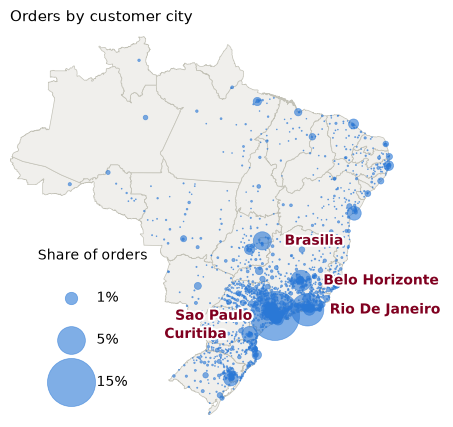

In [10]:
AREA = 8000   # marker area for a 100% share of orders
fig, ax = plt.subplots(figsize=(5, 9)); draw_brazil(ax)
df_shown = df_cities.filter(pl.col("orders") >= 5)   # skip the scatter of one-off towns; still 95% of orders
ax.scatter(df_shown["lng"], df_shown["lat"], s=AREA * df_shown["share"], c=BLUE, alpha=.6, ec=BLUE, lw=.5)
for r, (dx, dy) in zip(df_cities.head(5).iter_rows(named=True), [(-1, 0), (1, 0), (1, 0), (1, 0), (-1, 0)]):   # label left or right to avoid overlaps
    ax.annotate(r['customer_city'].title(), (r["lng"], r["lat"]), xytext=(16 * dx, dy),
                textcoords="offset points", fontsize=10, ha="right" if dx < 0 else "left", va="center", color="#800020", fontweight="bold", path_effects=[pe.withStroke(linewidth=3, foreground="white")])
for share in [.01, .05, .15]:   # empty scatters as size-legend entries
    ax.scatter([], [], s=AREA * share, c=BLUE, alpha=.6, ec=BLUE, lw=.5, label=f"{share:.0%}")
ax.legend(title="Share of orders", loc="lower left", frameon=False, labelspacing=2, borderpad=1.5)
ax.set_title("Orders by customer city", loc="left", fontsize=11);

Orders follow population: most come from the South-East coast, and São Paulo city alone accounts for 16%.

### Where the sellers are

#### By state

The table below shows that almost 60% of sellers are in São Paulo state but only 42% of orders. Each state's share of all orders and of all sellers with a sale in the period, and the share of its orders that are cross-state, meaning at least one seller is in another state.

In [11]:
df_sellers = tables["otab_sellers"].join(df_items.select("seller_id").unique(), on="seller_id")   # sellers with a sale in the period
df_state_mix = (df_orders.group_by(state="customer_state").agg(orders=pl.len(), cross_state_share=(~pl.col("in_state")).mean())   # mean skips orders without items
    .join(df_sellers.group_by(state="seller_state").agg(sellers=pl.len()), on="state", how="left").fill_null(0)
    .with_columns(order_share=pl.col("orders") / pl.sum("orders"), seller_share=pl.col("sellers") / pl.sum("sellers"))
    .select("state", "orders", "order_share", "sellers", "seller_share", "cross_state_share")
    .sort("orders", descending=True))
# with pl.Config(tbl_rows=10, float_precision=3):
df_state_mix.head()

state,orders,order_share,sellers,seller_share,cross_state_share
str,u32,f64,u32,f64,f64
"""SP""",41621,0.420024,1833,0.597458,0.242681
"""RJ""",12792,0.129092,169,0.055085,0.924015
"""MG""",11591,0.116972,243,0.079205,0.866394
"""RS""",5441,0.054909,126,0.041069,0.946376
"""PR""",5025,0.05071,347,0.113103,0.856167


#### Almost two-thirds of orders cross a state line, mostly out of São Paulo

An order is in-state when all its sellers are in the customer's state. On the map, each arrow is one of the 10 largest cross-state flows, running from the seller's state to the customer's. Arrow width scales with the number of orders, and labels show orders in thousands.

In [12]:
df_flows = (df_items.select("order_id", "seller_state", "customer_state").unique()   # an order with sellers in two states counts in both flows
    .group_by("seller_state", "customer_state").agg(orders=pl.len()))
cross_state = 1 - df_orders["in_state"].mean()   # in_state is null for orders without items
print(f"in-state: {1 - cross_state:.0%} of orders · cross-state: {cross_state:.0%}")
df_top = df_flows.filter(pl.col("seller_state") != pl.col("customer_state")).sort("orders", descending=True).head(10)
df_top

in-state: 36% of orders · cross-state: 64%


seller_state,customer_state,orders
str,str,u32
"""SP""","""RJ""",8436
"""SP""","""MG""",7569
"""SP""","""RS""",3656
"""SP""","""PR""",3168
"""PR""","""SP""",3006
"""MG""","""SP""",2628
"""SP""","""BA""",2384
"""SP""","""SC""",2364
"""SP""","""ES""",1490


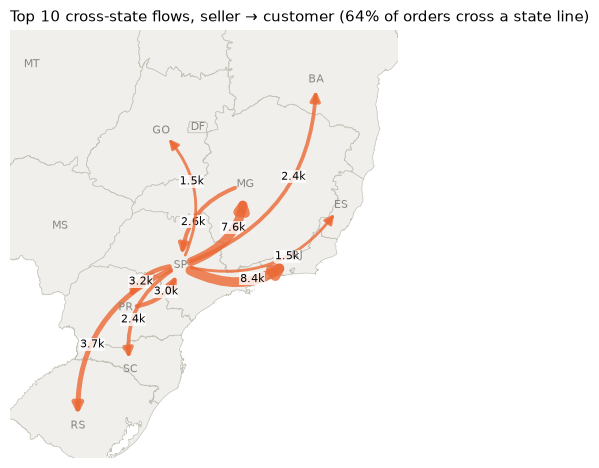

In [13]:
def centre(f):
    "Middle of a state's bounding box, from its border coordinates."
    g = f["geometry"]; pts = [pt for poly in (g["coordinates"] if g["type"] == "MultiPolygon" else [g["coordinates"]]) for pt in poly[0]]
    xs, ys = zip(*pts); return (min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2
centre = {f["properties"]["sigla"]: centre(f) for f in states}

RAD = .35   # arc bend: keeps the two directions of a state pair apart

def on_arc(a, b, t=.6):
    "Point a fraction t along matplotlib's arc3 curve from a to b (a quadratic Bezier)."
    (x1, y1), (x2, y2) = a, b
    cx, cy = (x1 + x2) / 2 + RAD * (y2 - y1), (y1 + y2) / 2 - RAD * (x2 - x1)
    return [(1 - t) ** 2 * p1 + 2 * t * (1 - t) * pc + t ** 2 * p2 for p1, pc, p2 in [(x1, cx, x2), (y1, cy, y2)]]

fig, ax = plt.subplots(figsize=(5, 9)); draw_brazil(ax)
for r in df_top.iter_rows(named=True):
    (x1, y1), (x2, y2) = centre[r["seller_state"]], centre[r["customer_state"]]
    ax.annotate("", (x2, y2), (x1, y1), arrowprops=dict(arrowstyle="-|>", mutation_scale=14, color=ORANGE, alpha=.8, shrinkA=8, shrinkB=8,
                lw=1 + 6 * r["orders"] / df_top["orders"].max(), connectionstyle=f"arc3,rad={RAD}"))
    ax.text(*on_arc((x1, y1), (x2, y2)), f"{r['orders'] / 1e3:.1f}k",
            fontsize=8, ha="center", va="center", bbox=dict(fc="white", ec="none", pad=.5, alpha=.8))
for s, (lng, lat) in centre.items(): ax.text(lng, lat, s, fontsize=8, color=GREY, ha="center", va="center", clip_on=True)
ax.set_xlim(-57, -38); ax.set_ylim(-32, -11)   # zoom on the South-East and South, where the big flows are
ax.set_title(f"Top 10 cross-state flows, seller → customer ({cross_state:.0%} of orders cross a state line)", loc="left", fontsize=11);

64% of orders cross a state line, and almost every big flow starts in São Paulo, where most sellers are. The longer these routes are, the more scope there is for late deliveries, which is what we look at next.

## 3 · Late orders analysis

### What counts as late

At checkout the customer is promised a delivery date (`order_estimated_delivery_date`, a date with no time). An order is **late** when it reaches the customer on a later day. `days_late` is the delivery day minus the promised day, so negative values mean early.

Orders that never arrive (stuck at `shipped`, canceled, unavailable…) are **not counted as late**. Looking at the order placement timestamps shows no increase towards the end of the measuring period, suggesting those orders have failed and will not be delivered after our measurement window (appendix, Never-delivered orders are lost or unavailable, not late).

In [14]:
df_delivered = (df_orders.filter(pl.col("order_status") == "delivered", pl.col("order_delivered_customer_date").is_not_null())
    .with_columns(days_late=(pl.col("order_delivered_customer_date").dt.date() - pl.col("order_estimated_delivery_date").dt.date()).dt.total_days())
    .with_columns(late=pl.col("days_late") > 0,
                  seller_late=pl.col("order_delivered_carrier_date") > pl.col("shipping_limit")))   # handed to the carrier after the deadline
df_not_delivered = df_orders.join(df_delivered, on="order_id", how="anti")
df_late = df_delivered.filter("late")

print(f"{df_orders.height:,} orders · {df_delivered.height:,} delivered, of which {df_late.height:,} late ({df_late.height / df_delivered.height:.1%}) · "
      f"{df_not_delivered.height:,} never delivered ({df_not_delivered.height / df_orders.height:.1%} of orders)")
print(f"Delivered late: median {df_late['days_late'].median():.0f} days late, a quarter more than {df_late['days_late'].quantile(.75):.0f} days")
print(f"The median delivered order arrives {-df_delivered['days_late'].median():.0f} days before the promised date")
days_to_deliver = (df_delivered["order_delivered_customer_date"] - df_delivered["order_purchase_timestamp"]).dt.total_hours() / 24
print(f"Median lead time from purchase: {df_orders['promised_days'].median():.1f} days promised, {days_to_deliver.median():.1f} days to deliver")
df_not_delivered.group_by("order_status").agg(orders=pl.len()).sort("orders", descending=True)

99,092 orders · 96,203 delivered, of which 6,531 late (6.8%) · 2,889 never delivered (2.9% of orders)
Delivered late: median 7 days late, a quarter more than 13 days
The median delivered order arrives 12 days before the promised date
Median lead time from purchase: 23.2 days promised, 10.2 days to deliver


order_status,orders
str,u32
"""shipped""",1097
"""unavailable""",602
"""canceled""",580
"""processing""",299
"""invoiced""",296
"""delivered""",8
"""created""",5
"""approved""",2


How far from the promised date orders arrive, and what customers think of it: average review score (1–5 stars) by `days_late`. Orders more than four weeks late are grouped in the 28+ bar.

Average review score: on time 4.29 · late 2.27 · more than a week late 1.70 · never delivered 1.76


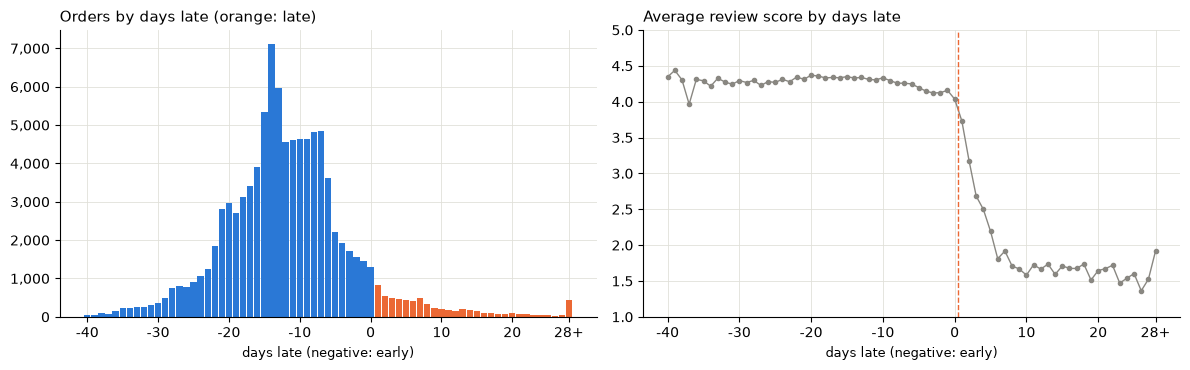

In [15]:
MAX_LATE = 28   # orders more than four weeks late are grouped in the "28+" bar
df_scores = tables["otab_order_reviews"].group_by("order_id").agg(pl.mean("review_score"))   # a few orders have several reviews
df_by_day = (df_delivered.select("order_id", days_late=pl.col("days_late").clip(upper_bound=MAX_LATE))
    .join(df_scores, on="order_id", how="left").group_by("days_late")
    .agg(orders=pl.len(), review_score=pl.mean("review_score")).sort("days_late")
    .filter(pl.col("days_late") >= -40))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(df_by_day["days_late"], df_by_day["orders"], color=[BLUE if d <= 0 else ORANGE for d in df_by_day["days_late"]], width=.9)
ax[0].set_title("Orders by days late (orange: late)", loc="left", fontsize=11)
ax[0].yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
df_enough = df_by_day.filter(pl.col("orders") >= 30)   # skip days with too few orders for a stable average
ax[1].plot(df_enough["days_late"], df_enough["review_score"], color=GREY, lw=1, marker="o", ms=3)
ax[1].axvline(.5, color=ORANGE, lw=1, ls="--")
ax[1].set_ylim(1, 5); ax[1].set_title("Average review score by days late", loc="left", fontsize=11)
for a in ax:
    a.set_xticks([-40, -30, -20, -10, 0, 10, 20, MAX_LATE], [-40, -30, -20, -10, 0, 10, 20, "28+"])
    a.set_xlabel("days late (negative: early)", fontsize=9)
plt.tight_layout()

score = lambda df: df.join(df_scores, on="order_id")["review_score"].mean()
print(f"Average review score: on time {score(df_delivered.filter(~pl.col('late'))):.2f} · late {score(df_late):.2f} · "
      f"more than a week late {score(df_late.filter(pl.col('days_late') > 7)):.2f} · never delivered {score(df_not_delivered):.2f}")

- **6.8% of delivered orders are late** (6,531 of 96,203). Another 2,889 orders (2.9%) never arrived.
- **Delivered late:** half are up to a week late, a quarter more than 13 days, and 6% more than four weeks.
- **The promise is padded.** The median order is promised in 23 days but delivered orders take a median of 10, so the median delivered order arrives 12 days early. A late order is one that missed a generous target.
- **Lateness is what customers punish.** Early or on time, reviews average about 4.3 stars whatever the margin. They fall as soon as the order is late (2.3 on average) and settle around 1.7 stars after a week. Orders that never arrive get a similar rating (1.8), close to orders more than a week late.
- **Late orders might cost some repeat business, though repeat buying is rare.** Only 3.1% of customers ever order twice. Once their first order has arrived, customers whose order was late come back a third less often than those whose order was on time: 0.8% against 1.2% within 90 days (appendix, A late order costs a third of repeat purchases).

#### What customers say about late orders

Looking at anecdotal reviews from late orders.

In [16]:
df_late_comments = (df_late.select("order_id", "days_late")
    .join(tables["otab_order_reviews"].select("order_id", "review_score", "review_comment_message"), on="order_id")
    .filter(pl.col("review_comment_message").str.strip_chars().str.len_chars() > 0)
    .sort("order_id"))   # fixed row order so the seeded sample is always the same
with pl.Config(fmt_str_lengths=400, tbl_width_chars=200, tbl_rows=5):
    display(df_late_comments.sample(5, seed=0).select("days_late", "review_score", "review_comment_message"))

days_late,review_score,review_comment_message
i64,i64,str
9,1,"""Não recebi o produto o prazo terminou ontem."""
13,1,"""Nunca mais eu comprou nas Américas """
8,1,"""Nao gostei de compra essa loja """
4,2,"""Gostaria de saber o motivo do não recebimento do produto que paguei."""
1,1,"""Preciso que faça estorno. O produto veio cheiro de queimado e não funciona """


Translation (by Claude, from Portuguese; the reviewers' own spelling mistakes are not kept):

| Days late | Score | Review |
|---|---|---|
| 9 | 1 | I haven't received the product; the deadline ran out yesterday. |
| 13 | 1 | I'll never buy from Americanas again. |
| 8 | 1 | I didn't like buying from this store. |
| 4 | 2 | I'd like to know why I haven't received the product I paid for. |
| 1 | 1 | I need a refund. The product came smelling burnt and doesn't work. |

- **Customers review before the parcel arrives!** Two of the five reviews were written while the order was still missing, though the order was delivered in the end. The low score records the wait.

#### Most late-order reviews are written before the parcel arrives

Reviews come from a satisfaction survey emailed to the customer. `review_creation_date` is the day the survey was sent and `review_answer_timestamp` when the customer answered. Comparing them with the delivery and promised dates shows when customers rate their order.

In [17]:
day = lambda c: pl.col(c).dt.date()
df_review_timing = (df_delivered.select("order_id", "late", "order_delivered_customer_date", "order_estimated_delivery_date")
    .join(tables["otab_order_reviews"].select("order_id", "review_score", "review_creation_date", "review_answer_timestamp"), on="order_id")
    .with_columns(sent_after_delivery=(day("review_creation_date") - day("order_delivered_customer_date")).dt.total_days(),
                  sent_after_promise=(day("review_creation_date") - day("order_estimated_delivery_date")).dt.total_days(),
                  days_to_answer=(pl.col("review_answer_timestamp") - pl.col("review_creation_date")).dt.total_hours() / 24,
                  before_delivery=day("review_creation_date") < day("order_delivered_customer_date")))
display(df_review_timing.group_by("late").agg(
    reviews=pl.len(), sent_after_delivery=pl.median("sent_after_delivery"), sent_after_promise=pl.median("sent_after_promise"),
    days_to_answer=pl.median("days_to_answer").round(1), before_delivery=pl.mean("before_delivery").round(3)).sort("late"))
display(df_review_timing.filter("late").group_by("before_delivery").agg(reviews=pl.len(), review_score=pl.mean("review_score").round(2)).sort("before_delivery"))

late,reviews,sent_after_delivery,sent_after_promise,days_to_answer,before_delivery
bool,u32,f64,f64,f64,f64
false,89681,1.0,-12.0,1.7,0.004
true,6406,-4.0,2.0,1.4,0.745


before_delivery,reviews,review_score
bool,u32,f64
false,1631,3.52
true,4775,1.84


- **The survey goes out the day after delivery, or soon after the promised date if the parcel hasn't come.** For on-time orders it is sent a median of 1 day after delivery. For late orders it is sent 2 days after the promised date.
- **So three-quarters of late-order reviews (75%) are written while the customer is still waiting.** Those average 1.8 stars. The quarter written after the parcel arrived average 3.5, still below the 4.3 for on-time orders.
- **The low rating of late orders mostly measures the uncertainty around the delivery** which is also why never-delivered orders score about the same (1.8). It fits the comments above ("I haven't received the product").
- **A delay costs less if customers are told in time.** Updating the delivery date before the survey goes out, or setting promises the carrier can keep, would protect ratings even when the parcel is late.

### Late rate over time

Share of delivered orders that were late, by week of purchase, next to the median delivery time promised at checkout. Known events are shaded: the orders placed in the run-up to each one, which were in the pipeline when it hit.

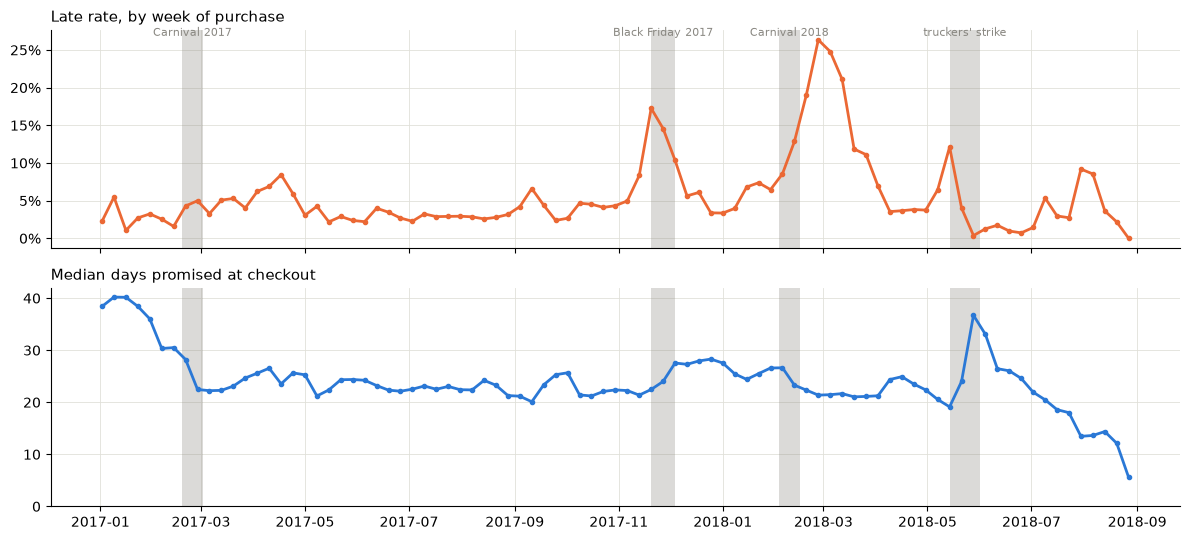

In [18]:
df_weekly = (df_delivered.group_by(week=pl.col("order_purchase_timestamp").dt.truncate("1w"))
    .agg(orders=pl.len(), late=pl.mean("late"),
         promised_days=pl.median("promised_days"))
    .sort("week"))
EVENTS = {   # purchase windows: the week before the event to its end (Black Friday: its week and the next)
    "Carnival 2017": (datetime(2017, 2, 18), datetime(2017, 3, 2)),
    "Black Friday 2017": (datetime(2017, 11, 20), datetime(2017, 12, 4)),
    "Carnival 2018": (datetime(2018, 2, 3), datetime(2018, 2, 15)),
    "truckers' strike": (datetime(2018, 5, 14), datetime(2018, 6, 1))}

fig, ax = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
ax[0].plot(df_weekly["week"], df_weekly["late"], color=ORANGE, lw=2, marker="o", ms=3)
ax[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax[0].set_title("Late rate, by week of purchase", loc="left", fontsize=11)
ax[1].plot(df_weekly["week"], df_weekly["promised_days"], color=BLUE, lw=2, marker="o", ms=3)
ax[1].set_ylim(0); ax[1].set_title("Median days promised at checkout", loc="left", fontsize=11)
for name, (start, end) in EVENTS.items():
    for a in ax: a.axvspan(start, end, color=GREY, alpha=.3, lw=0)
    ax[0].annotate(name, (start + (end - start) / 2, df_weekly["late"].max() * 1.02), fontsize=8, ha="center", color=GREY)
plt.tight_layout()

In [19]:
spike = pl.col("late") > 0.10   # spike week: more than 10% late
df_weekly_late = df_weekly.with_columns(late_orders=pl.col("late") * pl.col("orders"))
steady_rate = df_weekly_late.filter(~spike).select(pl.sum("late_orders") / pl.sum("orders")).item()
excess = df_weekly_late.filter(spike).select(pl.sum("late_orders") - steady_rate * pl.sum("orders")).item()
print(f"{df_weekly_late.filter(spike).height} spike weeks · steady rate {steady_rate:.1%} · "
      f"spikes add {excess:,.0f} late orders = {excess / df_weekly_late['late_orders'].sum():.0%} of all late orders")

11 spike weeks · steady rate 4.2% · spikes add 2,444 late orders = 37% of all late orders


- **Lateness comes in waves.** Most weeks run at 2–5% late, but three spells push it above 10%:
  - **Black Friday 2017:** 17% late, with the backlog lasting into December.
  - **February–March 2018:** the worst spell, up to 26% late. Carnival alone doesn't explain it; around Carnival 2017 the rate stayed near 5%.
  - **Mid-May 2018:** 12% late for orders placed just before the truckers' strike (21–31 May), which stopped them in transit.
- **The spikes add about 37% of all late orders;** the rest comes from the steady rate of about 4%.
- **Promises usually stretch to absorb a disruption, but not in February–March.** After Black Friday the median promise rose from 23 to 28 days, and after the strike from 21 to 37 days; both times lateness fell back within weeks (almost nothing was late in June). In February–March the promise did the opposite: it shortened from 27 to 22 days and stayed there for six weeks while more than 20% of orders arrived late. Promises then shortened again after the strike, to about 14 days by August, and lateness crept back to 9%.
- **The last weeks of August look good partly by artifact:** orders still in transit when the extract ends aren't counted yet.

**The February–March 2018 slowdown was nationwide and on the carrier side.** Sellers handed orders over as fast as usual, but parcels spent 3.5 more days with the carrier (median 10.8 vs 7.3). Every region was hit, **Rio de Janeiro most: 40% late against about 9% normally**. That fits the postal service's troubles at the time: cargo theft in Rio led Correios to restrict deliveries and add an emergency fee from 27 February ([Agência Brasil](https://agenciabrasil.ebc.com.br/economia/noticia/2018-04/tribunal-autoriza-correios-cobrar-taxa-por-encomenda-entregue-no-rio)), and its staff struck on 12–13 March ([Exame](https://exame.com/brasil/trabalhadores-dos-correios-entram-em-greve-nesta-segunda-feira/)). The data doesn't name the carrier, so these are possible links, not proven causes, and they don't explain the slowdown outside Rio.

### Seller or carrier?

Each item has a `shipping_limit_date`: the deadline for the seller to hand it to the carrier. `order_delivered_carrier_date` records the handover. For each late order we ask: **would it still have been late if the seller had handed it over on time?** (We take the seller's delay off the delivery date.)

- **seller:** the seller missed the deadline, and without that delay the order would have arrived on time;
- **both:** the seller missed the deadline, but the order would have been late anyway;
- **carrier:** the seller was on time.

shape: (3, 3)
┌─────────┬────────┬───────┐
│ cause   ┆ orders ┆ share │
│ ---     ┆ ---    ┆ ---   │
│ str     ┆ u32    ┆ f64   │
╞═════════╪════════╪═══════╡
│ seller  ┆ 809    ┆ 0.124 │
│ both    ┆ 1003   ┆ 0.154 │
│ carrier ┆ 4719   ┆ 0.723 │
└─────────┴────────┴───────┘
Seller delays account for 12% of all days late


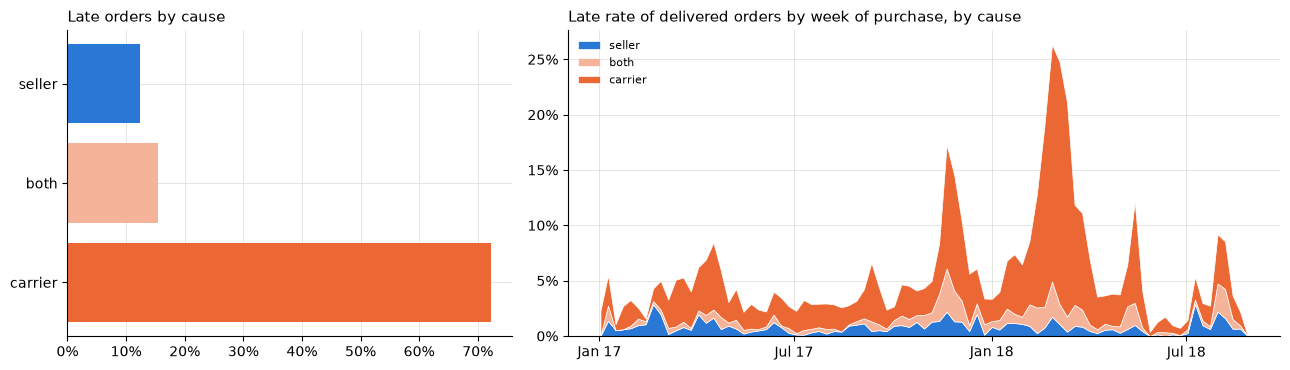

In [20]:
seller_delay = pl.when("seller_late").then(pl.col("order_delivered_carrier_date") - pl.col("shipping_limit")).otherwise(pl.duration(days=0))
late_anyway = (pl.col("order_delivered_customer_date") - seller_delay).dt.date() > pl.col("order_estimated_delivery_date").dt.date()
CAUSES = ["seller", "both", "carrier"]
df_late_cause = df_late.with_columns(
    cause=pl.when(~pl.col("seller_late")).then(pl.lit("carrier")).when(late_anyway).then(pl.lit("both")).otherwise(pl.lit("seller")),
    seller_days_late=pl.min_horizontal(seller_delay.dt.total_hours() / 24, "days_late"))   # days late due to the seller's delay
df_causes = (df_late_cause.group_by("cause").agg(orders=pl.len()).with_columns(share=(pl.col("orders") / pl.sum("orders")).round(3))
    .sort(pl.col("cause").replace_strict(CAUSES, range(3))))
print(df_causes)
print(f"Seller delays account for {df_late_cause['seller_days_late'].sum() / df_late_cause['days_late'].sum():.0%} of all days late")

df_delivered_cause = df_delivered.join(df_late_cause.select("order_id", "cause"), on="order_id", how="left")   # cause is null for on-time orders
df_weekly_cause = (df_delivered_cause.group_by(week=pl.col("order_purchase_timestamp").dt.truncate("1w"))
    .agg(*[(pl.col("cause") == c).fill_null(False).mean().alias(c) for c in CAUSES]).sort("week"))

COLORS = [BLUE, "#f5b49a", ORANGE]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), width_ratios=[1, 1.6])
ax[0].barh(df_causes["cause"], df_causes["share"], color=COLORS); ax[0].invert_yaxis()
ax[0].xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax[0].set_title("Late orders by cause", loc="left", fontsize=11)
ax[1].stackplot(df_weekly_cause["week"], *[df_weekly_cause[c] for c in CAUSES], labels=CAUSES, colors=COLORS, edgecolor="white", lw=.5)
ax[1].set_xticks(*MONTH_TICKS)
ax[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax[1].legend(frameon=False, fontsize=8, loc="upper left")
ax[1].set_title("Late rate of delivered orders by week of purchase, by cause", loc="left", fontsize=11)
plt.tight_layout()

- **Carriers cause most late orders.** In 72% the seller was on time, and in another 15% the order would have been late even without the seller's delay.
- **Sellers alone cause 12% of late orders, and 12% of all days late.** (Never-delivered orders, not counted here, lean the other way: about 60% never left the seller; see the appendix.)
- **The big spells are carrier spells.** Around Black Friday and in February–March 2018 the seller part barely moves; seller delays matter more in quiet weeks and in early August 2018.
- Missing the handover deadline goes with more late orders (21% of those orders arrive late, against 5% when the seller is on time), but those sellers may differ in other ways too.

### Distance

Distance is defined in the order features: straight-line distance to the farthest seller. Late rate of delivered orders by band, ±2 standard errors.

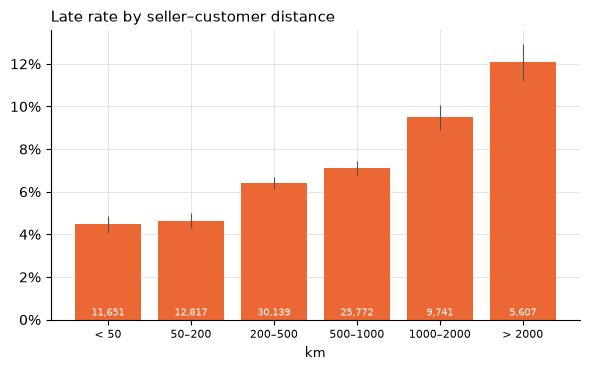

In [21]:
def late_by(key, data):
    "Late rate by `key`, with order counts and ±2 standard errors."
    return (data.group_by(key).agg(orders=pl.len(), late=pl.mean("late")).sort(key)
            .with_columns(err=2 * (pl.col("late") * (1 - pl.col("late")) / pl.col("orders")).sqrt()))

def rate_bars(ax, x, r, counts=False, **bar_kw):
    "Bars of a late_by() result with ±2 SE error bars; counts=True writes the number of orders at the base of each bar."
    ax.bar(x, r["late"], yerr=r["err"], error_kw={"lw": .8, "ecolor": "#52514e"}, **bar_kw)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    if counts:
        for b, n in zip(x, r["orders"]): ax.annotate(f"{n:,}", (b, 0), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=7, color="white")

def late_by_band(col, edges):
    "Late rate by band of `col`, with band labels such as '200–500'."
    labels = [f"< {edges[0]:g}"] + [f"{a:g}–{b:g}" for a, b in zip(edges, edges[1:])] + [f"> {edges[-1]:g}"]
    r = late_by("band", df_delivered.drop_nulls(col).with_columns(band=pl.sum_horizontal(pl.col(col) > e for e in edges)))
    return r.with_columns(label=pl.col("band").map_elements(labels.__getitem__, return_dtype=pl.String))

fig, ax = plt.subplots(figsize=(6, 3.8))
r = late_by_band("distance_km", [50, 200, 500, 1000, 2000])
rate_bars(ax, r["band"], r, counts=True, color=ORANGE)
ax.set_xticks(r["band"], r["label"], fontsize=8); ax.set_xlabel("km", fontsize=9)
ax.set_title("Late rate by seller–customer distance", loc="left", fontsize=11)
plt.tight_layout()

Numbers at the base of the bars are orders.

- **Distance matters a lot.** Under 200 km about 4.5% of orders are late; beyond 2,000 km 12%.

### Which routes?

A carrier-late order is one the carrier made late (cause carrier or both above). Routes run from the main seller's state to the customer's state. For each route, excess late orders are its carrier-late orders minus what it would have at the overall carrier-late rate. Routes are first put in five groups: São Paulo to Rio de Janeiro, São Paulo to the nine North-East states, São Paulo to the other states, other cross-state routes, and routes within one state.

carrier-late rate 5.9%, 3.6% in calm weeks


route_group,orders,carrier_late,rate,rate_calm_weeks,carrier_days,share_orders,share_carrier_late,excess,share_excess
str,u32,u32,f64,f64,f64,f64,f64,f64,f64
"""SP → Rio de Janeiro""",8141,1081,0.133,0.061,9.083,0.085,0.189,596.786,0.376
"""SP → North-East""",6342,824,0.130,0.092,14.208,0.066,0.144,446.788,0.282
"""SP → other states""",23107,1447,0.063,0.028,9.042,0.240,0.253,72.633,0.046
"""other cross-state""",23998,1151,0.048,0.031,8.167,0.249,0.201,-276.363,null
"""within one state""",34615,1219,0.035,0.028,3.625,0.360,0.213,-839.845,null


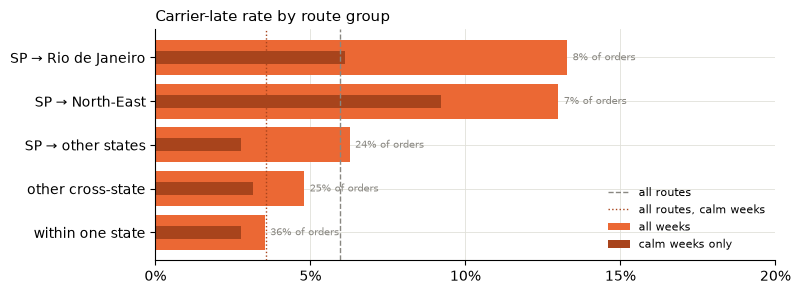

In [22]:
df_route = (df_delivered_cause.join(tables["otab_sellers"].select(main_seller="seller_id", seller_state="seller_state"), on="main_seller")
    .with_columns(route=pl.col("seller_state") + " → " + pl.col("customer_state"),
                  route_group=pl.when(pl.col("seller_state") == pl.col("customer_state")).then(pl.lit("within one state"))
                      .when(pl.col("seller_state") != "SP").then(pl.lit("other cross-state"))
                      .when(pl.col("customer_state") == "RJ").then(pl.lit("SP → Rio de Janeiro"))
                      .when(pl.col("region") == "North-East").then(pl.lit("SP → North-East"))
                      .otherwise(pl.lit("SP → other states")),
                  carrier_late=pl.col("cause").is_in(["carrier", "both"]).fill_null(False),
                  carrier_days=(pl.col("order_delivered_customer_date") - pl.col("order_delivered_carrier_date")).dt.total_hours() / 24))
carrier_rate = df_route["carrier_late"].mean()

def placed_during(*names):
    "True for orders placed in any of the named event windows."
    return pl.any_horizontal(pl.col("order_purchase_timestamp").is_between(*EVENTS[n], closed="left") for n in names)
calm_weeks = ~placed_during(*EVENTS) & ~pl.col("order_purchase_timestamp").is_between(datetime(2018, 2, 1), datetime(2018, 4, 1), closed="left")   # also leaves out the Feb–Mar 2018 spell
df_routes = (df_route.group_by("route", "route_group").agg(
        orders=pl.len(), carrier_late=pl.sum("carrier_late"), rate=pl.mean("carrier_late"),
        rate_calm_weeks=pl.col("carrier_late").filter(calm_weeks).mean(), carrier_days=pl.median("carrier_days"))
    .with_columns(excess=pl.col("carrier_late") - pl.col("orders") * carrier_rate).sort("excess", descending=True))
total_excess = df_routes.filter(pl.col("excess") > 0)["excess"].sum()   # all positive route excess

GROUPS = ["SP → Rio de Janeiro", "SP → North-East", "SP → other states", "other cross-state", "within one state"]
df_route_groups = (df_route.group_by("route_group").agg(
        orders=pl.len(), carrier_late=pl.sum("carrier_late"), rate=pl.mean("carrier_late"),
        rate_calm_weeks=pl.col("carrier_late").filter(calm_weeks).mean(), carrier_days=pl.median("carrier_days"))
    .with_columns(share_orders=pl.col("orders") / df_route.height, share_carrier_late=pl.col("carrier_late") / pl.sum("carrier_late"),
                  excess=pl.col("carrier_late") - pl.col("orders") * carrier_rate)
    .with_columns(share_excess=pl.when(pl.col("excess") > 0).then(pl.col("excess") / total_excess))
    .sort(pl.col("route_group").replace_strict(GROUPS, range(len(GROUPS)))))
print(f"carrier-late rate {carrier_rate:.1%}, {df_route.filter(calm_weeks)['carrier_late'].mean():.1%} in calm weeks")
with pl.Config(float_precision=3, tbl_cols=-1):
    display(df_route_groups)

fig, ax = plt.subplots(figsize=(8, 3))
bars = df_route_groups.reverse()
ax.barh(bars["route_group"], bars["rate"], color=ORANGE, label="all weeks")
ax.barh(bars["route_group"], bars["rate_calm_weeks"], height=.3, color="#a8441c", label="calm weeks only")
ax.axvline(carrier_rate, color=GREY, lw=1, ls="--", label="all routes")
ax.axvline(df_route.filter(calm_weeks)["carrier_late"].mean(), color="#a8441c", lw=1, ls=":", label="all routes, calm weeks")
for y, (rate, share) in enumerate(zip(bars["rate"], bars["share_orders"])):
    ax.annotate(f"{share:.0%} of orders", (rate, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=7, color=GREY)
ax.set_xlim(0, .2); ax.set_xticks([0, .05, .1, .15, .2]); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("Carrier-late rate by route group", loc="left", fontsize=11);

- **Two route groups, 15% of orders, hold a third of carrier-late orders and two-thirds of the excess:** São Paulo to Rio de Janeiro and São Paulo to the North-East. The other São Paulo routes are close to average.
- **They fail differently:**
  - **SP → Rio is mostly the spells:** 13% carrier-late overall but 6.1% in calm weeks, with a normal 9 days with the carrier.
  - **SP → North-East is structural:** still 9.2% in calm weeks, two and a half times the 3.6% average, with 14 days with the carrier.

## 4 · Recommended course of action

1. **Fix the hotspot routes.** SP → Rio and SP → North-East hold most of the excess carrier delay (carrier-late orders above the national rate). Set route-level on-time targets for carriers and add alternative carriers.
2. **Expand the seller base outside São Paulo.** Longer delivery distances bring more risk and delays. Matching sellers and customers closer to each other improves the experience for both.
3. **Set promises by route and season.** Lengthen promises for the North-East and before foreseeable peaks such as Black Friday.
4. **Improve processes and data collection.** Fix the communication about delayed orders, ask for reviews after delivery, record delivery per parcel, and clear orders stuck as `shipped`.

## Appendix

### The North-East's promise covers its slower deliveries, but not their long tail

Padding is the promised days minus the days the parcel actually took, both counted from purchase; negative padding means the parcel arrived late. Calm weeks only, so the event windows and the February–March 2018 spell do not blur the structural picture. The North-East is the customer's region, whatever the seller's state.

area,orders,late,promised,delivered,delivered_p90,delivered_p95,padding,extra_days_for_95_on_time
str,u32,f64,f64,f64,f64,f64,f64,f64
"""Brazil""",73752,0.043,23.2,9.5,20.8,26.0,12.3,0.7
"""North-East""",7048,0.094,30.5,16.2,30.5,37.2,13.2,7.8


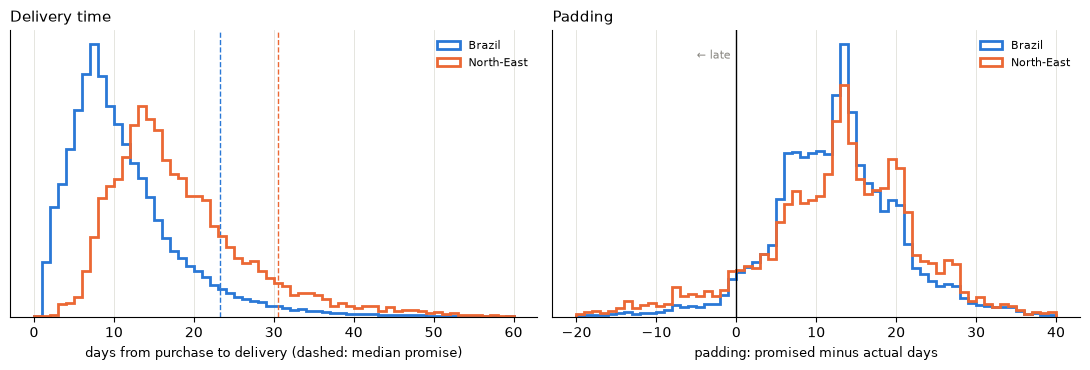

In [23]:
df_padding = (df_delivered.filter(calm_weeks)
    .with_columns(delivery_days=(pl.col("order_delivered_customer_date") - pl.col("order_purchase_timestamp")).dt.total_hours() / 24)
    .with_columns(padding=pl.col("promised_days") - pl.col("delivery_days")))
df_padding_areas = pl.concat([df_padding.with_columns(area=pl.lit("Brazil")),
                              df_padding.filter(pl.col("region") == "North-East").with_columns(area=pl.lit("North-East"))])
with pl.Config(tbl_cols=-1):
    display(df_padding_areas.group_by("area", maintain_order=True).agg(
        orders=pl.len(), late=pl.mean("late").round(3), promised=pl.median("promised_days").round(1),
        delivered=pl.median("delivery_days").round(1), delivered_p90=pl.col("delivery_days").quantile(.9).round(1),
        delivered_p95=pl.col("delivery_days").quantile(.95).round(1), padding=pl.median("padding").round(1),
        extra_days_for_95_on_time=(-pl.col("padding").quantile(.05)).clip(0).round(1)))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for area, color in [("Brazil", BLUE), ("North-East", ORANGE)]:
    d = df_padding_areas.filter(pl.col("area") == area)
    axes[0].hist(d["delivery_days"], bins=np.arange(0, 61), density=True, histtype="step", lw=2, color=color, label=area)
    axes[0].axvline(d["promised_days"].median(), color=color, ls="--", lw=1)
    axes[1].hist(d["padding"], bins=np.arange(-20, 41), density=True, histtype="step", lw=2, color=color, label=area)
axes[0].set_xlabel("days from purchase to delivery (dashed: median promise)", fontsize=9)
axes[1].axvline(0, color="black", lw=1)
axes[1].annotate("← late", (0, axes[1].get_ylim()[1] * .9), xytext=(-4, 0), textcoords="offset points", ha="right", fontsize=8, color=GREY)
axes[1].set_xlabel("padding: promised minus actual days", fontsize=9)
for ax, title in zip(axes, ["Delivery time", "Padding"]):
    ax.set_yticks([]); ax.legend(frameon=False, fontsize=8); ax.set_title(title, loc="left", fontsize=11)
plt.tight_layout()

- **The extra promise matches the slower typical delivery.** North-East orders are promised 30.5 days against 23 for Brazil, and take 16 days against 9.5, so the median padding is about the same (13 days against 12).
- **It does not cover the long tail.** In Brazil 9 in 10 parcels arrive by day 21, two days before the promise; in the North-East the 90th percentile is day 30.5, exactly the promise. The North-East's padding has a fatter tail below zero.
- **So the North-East is late twice as often even in calm weeks** (9.4% against 4.3%). Getting 95% of its orders on time would take about 8 more days of promise; for Brazil as a whole, under 1.
- The promise seems to follow the typical delivery time of a destination, not how spread out it is.

### Heavy parcels are late only slightly more often

Weight is defined in the order features: total product weight. Late rate of delivered orders by band, ±2 standard errors; numbers at the base of the bars are orders.

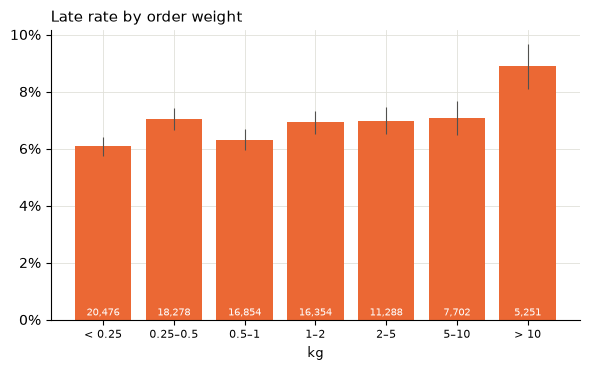

In [24]:
fig, ax = plt.subplots(figsize=(6, 3.8))
r = late_by_band("weight_kg", [.25, .5, 1, 2, 5, 10])
rate_bars(ax, r["band"], r, counts=True, color=ORANGE)
ax.set_xticks(r["band"], r["label"], fontsize=8); ax.set_xlabel("kg", fontsize=9)
ax.set_title("Late rate by order weight", loc="left", fontsize=11)
plt.tight_layout()

The late rate is 6–7% up to 10 kg and 9% above. Heavy parcels also tend to travel further, which may explain part of the gap.

### A small group of sellers causes most seller-only delays

Sellers are ranked by the number of late orders they caused (late only because of the seller's delay), and the curve shows what share of those late orders the top sellers account for. For comparison, the other curves rank sellers by all orders and by all late orders.

In [25]:
df_by_seller = df_delivered_cause.group_by("main_seller").agg(
    orders=pl.len(), late=pl.col("late").sum(), seller_caused=(pl.col("cause") == "seller").sum())

def top_share(col, top):
    "Share of `col` held by the top `top` fraction of sellers, ranked by `col`."
    s = df_by_seller[col].sort(descending=True)
    return s.head(round(top * len(s))).sum() / s.sum()

print(f"{df_by_seller.height:,} sellers with delivered orders · {(df_by_seller['seller_caused'] > 0).mean():.0%} caused at least one late order")
top5 = df_by_seller.sort("seller_caused", "orders", descending=True).head(round(.05 * df_by_seller.height))
print(f"Top 5% by seller-caused late orders: {top5['seller_caused'].sum() / df_by_seller['seller_caused'].sum():.0%} of them, from {top5['orders'].sum() / df_by_seller['orders'].sum():.0%} of orders")
pl.DataFrame({"top sellers": ["1%", "5%", "10%", "20%"]} | {col: [round(top_share(col, t), 3) for t in [.01, .05, .1, .2]] for col in ["orders", "late", "seller_caused"]})

2,936 sellers with delivered orders · 12% caused at least one late order
Top 5% by seller-caused late orders: 74% of them, from 34% of orders


top sellers,orders,late,seller_caused
str,f64,f64,f64
"""1%""",0.261,0.296,0.36
"""5%""",0.529,0.586,0.742
"""10%""",0.677,0.737,0.923
"""20%""",0.823,0.874,1.0


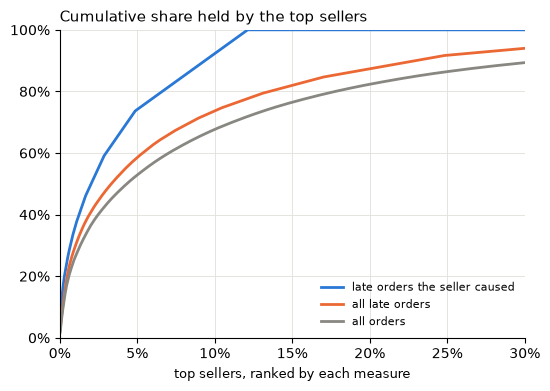

In [26]:
fig, ax = plt.subplots(figsize=(6, 4))
for col, color, label in [("seller_caused", BLUE, "late orders the seller caused"), ("late", ORANGE, "all late orders"), ("orders", GREY, "all orders")]:
    s = df_by_seller[col].sort(descending=True)
    ax.plot(np.arange(1, len(s) + 1) / len(s), s.cum_sum() / s.sum(), color=color, lw=2, label=label)
ax.set_xlim(0, .3); ax.set_ylim(0, 1)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("top sellers, ranked by each measure", fontsize=9); ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("Cumulative share held by the top sellers", loc="left", fontsize=11);

- Only 12% of the 2,936 sellers ever made an order late on their own.
- The top 5% (about 150) caused 74% of those late orders while handling only 34% of all orders.
- So there is a fringe of sellers with poor handover discipline, though seller-only delays are just 12% of late orders. Part of the gap is chance: ranking sellers by their own late orders also picks out some that were merely unlucky.

### Payment method barely affects lateness

Each order has one or more payments (`otab_order_payments`). The main method is the one covering most of the amount. A boleto is a bank slip paid after checkout: the order is approved only once it is paid, but the delivery promise is counted from the purchase.

shape: (4, 4)
┌─────────────┬────────┬───────┬──────────────────────────┐
│ main_method ┆ orders ┆ late  ┆ median_hours_to_approval │
│ ---         ┆ ---    ┆ ---   ┆ ---                      │
│ str         ┆ u32    ┆ f64   ┆ f64                      │
╞═════════════╪════════╪═══════╪══════════════════════════╡
│ credit_card ┆ 72612  ┆ 0.067 ┆ 0.0                      │
│ boleto      ┆ 19140  ┆ 0.073 ┆ 29.0                     │
│ voucher     ┆ 2970   ┆ 0.061 ┆ 0.0                      │
│ debit_card  ┆ 1481   ┆ 0.053 ┆ 0.0                      │
└─────────────┴────────┴───────┴──────────────────────────┘
251 orders (0.3%) where payments differ from price_incl_delivery by more than R$0.05: 234 paid more (median R$ 7.29), 17 paid less · late rate 5.2%


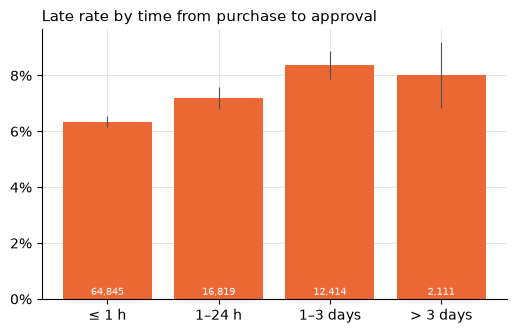

In [27]:
df_per_order_payment = tables["otab_order_payments"].group_by("order_id").agg(
    paid=pl.sum("payment_value"), main_method=pl.col("payment_type").sort_by("payment_value").last(), installments=pl.max("payment_installments"))
df_paid = df_delivered.join(df_per_order_payment, on="order_id").with_columns(paid_minus_price=pl.col("paid") - pl.col("price_incl_delivery"))

print(df_paid.group_by("main_method").agg(orders=pl.len(), late=pl.mean("late").round(3), median_hours_to_approval=pl.median("approval_hours"))
      .sort("orders", descending=True))
df_mismatch = df_paid.filter(pl.col("paid_minus_price").abs() > .05)
print(f"{df_mismatch.height} orders ({df_mismatch.height / df_paid.height:.1%}) where payments differ from price_incl_delivery by more than R$0.05: "
      f"{(df_mismatch['paid_minus_price'] > 0).sum()} paid more (median R$ {df_mismatch.filter(pl.col('paid_minus_price') > 0)['paid_minus_price'].median():.2f}), "
      f"{(df_mismatch['paid_minus_price'] < 0).sum()} paid less · late rate {df_mismatch['late'].mean():.1%}")

edges = [1, 24, 72]; labels = ["≤ 1 h", "1–24 h", "1–3 days", "> 3 days"]
r = late_by("band", df_paid.drop_nulls("approval_hours").with_columns(band=pl.sum_horizontal(pl.col("approval_hours") > e for e in edges)))
fig, ax = plt.subplots(figsize=(6, 3.5))
rate_bars(ax, r["band"], r, counts=True, color=ORANGE)
ax.set_xticks(r["band"], [labels[b] for b in r["band"]])
ax.set_title("Late rate by time from purchase to approval", loc="left", fontsize=11);

- **Payment method matters little.** Boleto orders are late slightly more often (7.3% vs 6.7% for cards), debit cards slightly less (5.3%).
- **The mechanism is the approval delay.** Boletos take a median of 29 hours to be paid, and that time comes out of the same 23-day promise. Orders approved within an hour are late 6.3% of the time, those approved after more than a day about 8%. 
- **Payments match prices.** Only 0.3% of orders differ by more than 5 centavos, mostly small overpayments that grow with the number of instalments (likely instalment interest). They are not late more often.

### A late order costs a third of repeat purchases, though repeat buying is rare

A customer is a `customer_unique_id`. What matters is whether they order again once they know how their first order went. That point is the delivery date, or the promised date for an order that never arrived. A customer **comes back** when they order again within 90 days of that point. Orders placed earlier, while the first one was still on its way, can't be a reaction to it and are counted separately. Only first orders whose outcome was known before June 2018 count, so every customer has a full 90 days to return before the extract ends. Error bars: ±2 standard errors.

In [28]:
n_customers = df_orders["customer_unique_id"].n_unique()
repeaters = df_orders.group_by("customer_unique_id").agg(n=pl.len()).filter(pl.col("n") > 1)
print(f"{n_customers:,} customers · {repeaters.height:,} ({repeaters.height / n_customers:.1%}) placed more than one order · "
      f"{df_orders.height - n_customers:,} repeat orders ({(df_orders.height - n_customers) / df_orders.height:.1%} of orders)")

cust = "customer_unique_id"
df_first = (df_orders.sort("order_purchase_timestamp", "order_id")
    .with_columns(known=pl.coalesce("order_delivered_customer_date", "order_estimated_delivery_date").first().over(cust))   # first order's outcome is known
    .with_columns(is_first=pl.int_range(pl.len()).over(cust) == 0,
                  days_after_known=(pl.col("order_purchase_timestamp") - pl.col("known")).dt.total_hours() / 24)
    .group_by(cust, maintain_order=True).agg(
        pl.col("order_id").first(), pl.col("known").first(),
        before_known=pl.col("days_after_known").filter(~pl.col("is_first")).lt(0).any(),  #lt is "less than"
        came_back=pl.col("days_after_known").filter(~pl.col("is_first")).is_between(0, 90).any())
    .filter(pl.col("known") < datetime(2018, 6, 1))
    .join(df_delivered.select("order_id", "late"), on="order_id", how="left")
    .with_columns(first_order=pl.when(pl.col("late").is_null()).then(pl.lit("never delivered"))
                             .when("late").then(pl.lit("late")).otherwise(pl.lit("on time"))))
print(f"{df_first['before_known'].mean():.1%} of customers reordered before knowing how their first order went, "
      f"{df_first['came_back'].mean():.1%} came back after")
r = (df_first.group_by("first_order").agg(customers=pl.len(), reordered_before=pl.mean("before_known"), came_back=pl.mean("came_back"))
     .with_columns(err=2 * (pl.col("came_back") * (1 - pl.col("came_back")) / pl.col("customers")).sqrt())
     .sort("came_back", descending=True))
with pl.Config(float_precision=4):
    display(r)

95,774 customers · 2,975 (3.1%) placed more than one order · 3,318 repeat orders (3.3% of orders)
1.4% of customers reordered before knowing how their first order went, 1.2% came back after


first_order,customers,reordered_before,came_back,err
str,u32,f64,f64,f64
"""on time""",67504,0.0131,0.0119,0.0008
"""never delivered""",2374,0.0249,0.0110,0.0043
"""late""",5205,0.0159,0.0079,0.0025


**Permutation test.** If the outcome of the first order made no difference, the labels "late" and "on time" would be interchangeable. So shuffle them at random among the same customers many times, recompute the gap in return rates each time, and count how often a shuffled gap is at least as large (either way) as the observed one. That share is the empirical p-value.

In [29]:
def permutation_p(y, label, n=10_000, seed=0):
    "Observed gap in mean `y` (label True minus False) and the share of n random relabellings with a gap at least as large in absolute value."
    rng = np.random.default_rng(seed)
    y, label = np.asarray(y, float), np.asarray(label, bool)
    gap = lambda l: y[l].mean() - y[~l].mean()
    observed = gap(label)
    shuffled = np.array([gap(rng.permutation(label)) for _ in range(n)])
    return observed, (np.abs(shuffled) >= abs(observed)).mean()

for group in ["late", "never delivered"]:
    df_pair = df_first.filter(pl.col("first_order").is_in([group, "on time"]))
    gap, p = permutation_p(df_pair["came_back"], df_pair["first_order"] == group)
    print(f"{group} vs on time: came back {gap:+.2%} · empirical p = {p:.4f} (10,000 shuffles)")

late vs on time: came back -0.40% · empirical p = 0.0122 (10,000 shuffles)


never delivered vs on time: came back -0.09% · empirical p = 0.6945 (10,000 shuffles)


- **Repeat buying is rare.** Only 3.1% of customers placed more than one order, and repeat orders are 3.3% of all orders.
- **Many reorders come too early to be a reaction.** 1.4% of customers ordered again before their first order arrived (or before its promised date had passed), slightly more than the 1.2% who came back after. These early reorders include baskets split into several orders. They are more common after late and never-delivered orders, simply because the customer waited longer.
- **Once customers know, a late order costs a third of the returns.** 0.8% of customers whose first order was late came back within 90 days, against 1.2% when it was on time. The gap is unlikely to be chance: shuffling the late and on-time labels 10,000 times gives a gap this large only 1.2% of the time (empirical p ≈ 0.01).
- **Never-delivered first orders sit in between (1.1%)**, and that gap with on-time orders could easily be chance (empirical p ≈ 0.7). Some of those returns are probably customers reordering the item that never came.
- **The cost is real but small in absolute terms,** because so few customers return anyway. Roughly 20 lost returning customers per 5,000 late first orders. The bigger cost is the reviews (§3, What counts as late).

### Categories have little effect on lateness

Late rate of delivered orders for the 15 categories with the most orders, ±2 standard errors. An order with items in two categories counts in both.

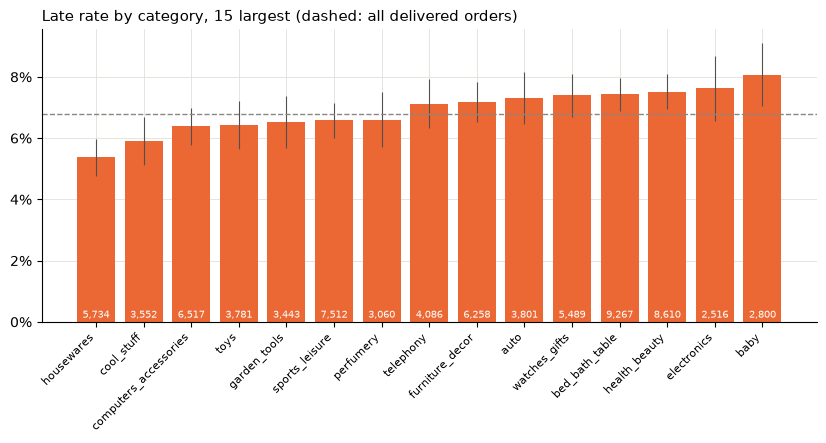

In [30]:
df_order_cat = df_items.select("order_id", "category").unique()
top_cats = df_order_cat.group_by("category").agg(orders=pl.len()).sort("orders", descending=True).head(15)
r = late_by("category", df_delivered.join(df_order_cat, on="order_id").join(top_cats, on="category", how="semi")).sort("late")
fig, ax = plt.subplots(figsize=(10, 3.8))
rate_bars(ax, range(r.height), r, counts=True, color=ORANGE)
ax.axhline(df_delivered["late"].mean(), color=GREY, lw=1, ls="--")   # all delivered orders
ax.set_xticks(range(r.height), r["category"], rotation=45, ha="right", fontsize=8)
ax.set_title("Late rate by category, 15 largest (dashed: all delivered orders)", loc="left", fontsize=11);

**Category matters little.** Among the 15 largest categories the late rate runs from 5.4% (housewares) to 8.1% (baby), and most error bars overlap the overall 6.8%.

### Never-delivered orders are lost or unavailable, not late

Orders placed Jan 2017 – Aug 2018 that never reached the customer, by status. The question is whether they are missing because the data stops (still on their way at the end of the extract) or because something went wrong. The chart shows each status as a share of the orders placed that week.

Last recorded delivery 17 Oct 2018, last recorded handover 11 Sep 2018
Never-delivered orders promised after the last recorded delivery: 0


order_status,orders,median_placed,placed_jul_aug_2018,handed_over
str,u32,date,u32,f64
"""shipped""",1097,2018-01-08,107,1.0
"""unavailable""",602,2017-10-17,25,0.0
"""canceled""",580,2018-01-30,125,0.12
"""processing""",299,2017-09-20,1,0.0
"""invoiced""",296,2017-11-22,36,0.0
"""delivered""",8,2018-06-23,3,0.88
"""created""",5,2017-12-05,0,0.0
"""approved""",2,2017-03-17,0,0.0


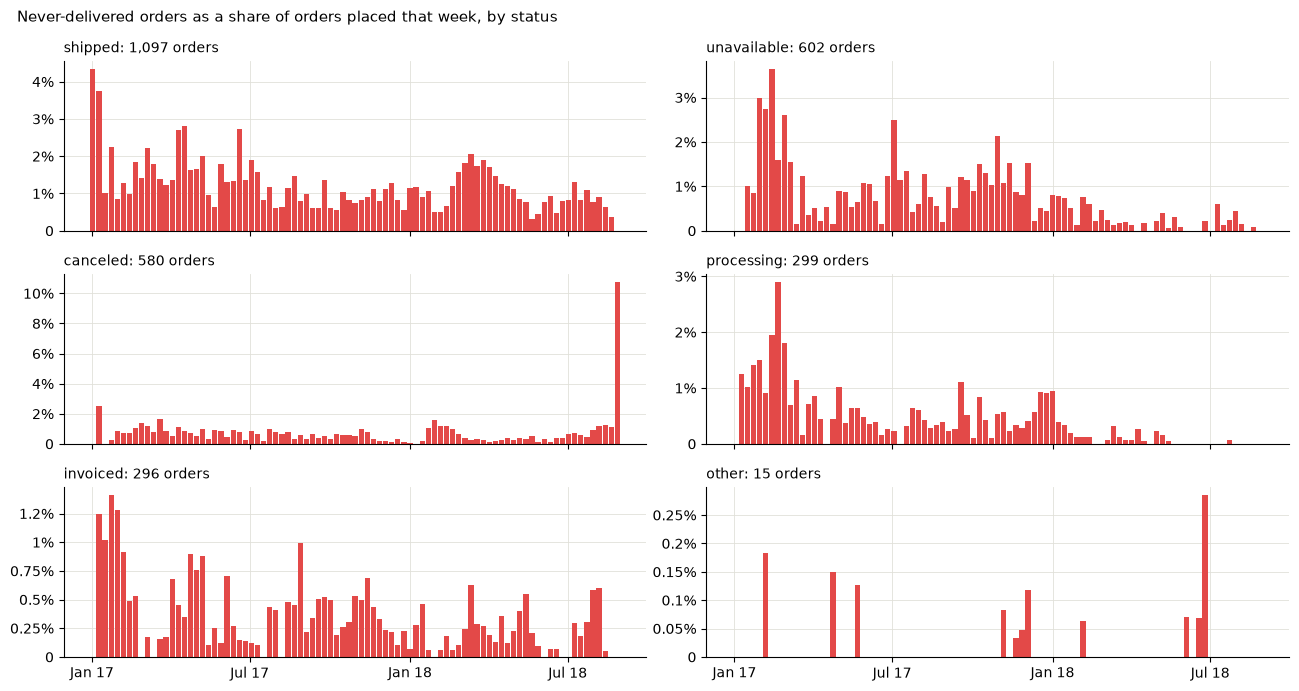

In [31]:
tbl = tables["otab_orders"]
last_delivery, last_handover = tbl["order_delivered_customer_date"].max(), tbl["order_delivered_carrier_date"].max()
print(f"Last recorded delivery {last_delivery:%d %b %Y}, last recorded handover {last_handover:%d %b %Y}")
print(f"Never-delivered orders promised after the last recorded delivery: {(df_not_delivered['order_estimated_delivery_date'] > last_delivery).sum()}")
display(df_not_delivered.group_by("order_status").agg(
    orders=pl.len(), median_placed=pl.median("order_purchase_timestamp").dt.date(),
    placed_jul_aug_2018=(pl.col("order_purchase_timestamp") >= datetime(2018, 7, 1)).sum(),
    handed_over=pl.col("order_delivered_carrier_date").is_not_null().mean().round(2)).sort("orders", descending=True))

STATUSES = ["shipped", "unavailable", "canceled", "processing", "invoiced"]
week = pl.col("order_purchase_timestamp").dt.truncate("1w")
df_nd_weekly = (df_orders.group_by(week=week).agg(total=pl.len())
    .join(df_not_delivered.with_columns(status=pl.when(pl.col("order_status").is_in(STATUSES)).then("order_status").otherwise(pl.lit("other")))
          .group_by(week=week).agg([(pl.col("status") == s).sum().alias(s) for s in STATUSES + ["other"]]), on="week", how="left")
    .fill_null(0).sort("week"))

fig, axes = plt.subplots(3, 2, figsize=(13, 7), sharex=True)
for ax, s in zip(axes.flat, STATUSES + ["other"]):
    ax.bar(df_nd_weekly["week"], df_nd_weekly[s] / df_nd_weekly["total"], width=6, color=RED)
    ax.set_title(f"{s}: {df_nd_weekly[s].sum():,} orders", loc="left", fontsize=10)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.2g}" if v == 0 else f"{v * 100:.2g}%")
    ax.set_xticks(*MONTH_TICKS)
fig.suptitle("Never-delivered orders as a share of orders placed that week, by status", x=.01, ha="left", fontsize=11)
plt.tight_layout()

- **Not the end of the window.** Every never-delivered order was promised before the last recorded delivery (17 Oct 2018). If these were parcels still on their way, they would pile up in the last weeks. Instead the share is highest at the start: about 6–7% of orders in Jan–Feb 2017, about 3% through 2017 and 1–2.5% in 2018.
- **About 60% never left the seller.** `unavailable` (no stock), `processing` and `invoiced` were never handed to the carrier, and neither were 88% of cancellations. They are concentrated in 2017 and fade as the platform matures.
- **The other 40% were lost with the carrier.** `shipped` orders were handed over and never recorded as delivered, typically about ten months before the data ends. They follow the same disruptions as late orders, with a bump after Carnival 2018.
- **The window only matters at the very end.** Cancellations jump to about 10% of orders placed in the last week of Aug 2018, and `invoiced` rises a little in Jul–Aug 2018. The handover records stop on 11 Sep 2018, five weeks before the last delivery. That is roughly 100–150 orders.
- **So they are not late orders.** They are a separate failure: stock-outs and stuck orders on the seller side, lost parcels on the carrier side. Customers rate them as badly as very late orders (§3).
- **`other`** is the 8 orders marked `delivered` with no delivery date (Data quality), plus 7 `created` or `approved`.

### Other trends, not about lateness

What sells and when orders are placed and delivered. Background for the analysis, not part of it.

#### Ten of 74 categories make most of the sales, led by health and beauty

Top 10 categories by sales. Bars show each category's share of orders and of sales (prices excluding delivery).

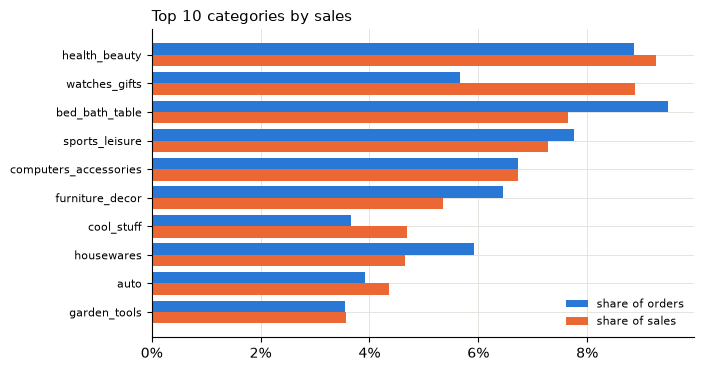

In [32]:
df_cat = (df_items.group_by("category").agg(orders=pl.col("order_id").n_unique(), sales=pl.sum("price_excl_delivery"))
    .with_columns(pl.col("orders") / pl.col("orders").sum(), pl.col("sales") / pl.col("sales").sum())
    .sort("sales").tail(10))

fig, ax = plt.subplots(figsize=(7, 4)); rows = range(df_cat.height)
ax.barh([i + .2 for i in rows], df_cat["orders"], .4, color=BLUE, label="share of orders")
ax.barh([i - .2 for i in rows], df_cat["sales"], .4, color=ORANGE, label="share of sales")
ax.set_yticks(list(rows), df_cat["category"], fontsize=8); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(frameon=False, fontsize=8, loc="lower right"); ax.set_title("Top 10 categories by sales", loc="left", fontsize=11);

#### Orders grew through 2017, then flattened at about 230 a day

Average orders per hour, by hour of day and across the week, plus daily orders over the whole period. The hourly profiles use 11 ordinary weeks (5 Mar – 20 May 2018), so one-off spikes like Black Friday and the truckers' strike don't distort them. Averages include hours with no orders. With only 20 months of data, a month-of-year pattern can't be told apart from growth, so the daily series is shown as it is, with a 7-day average.

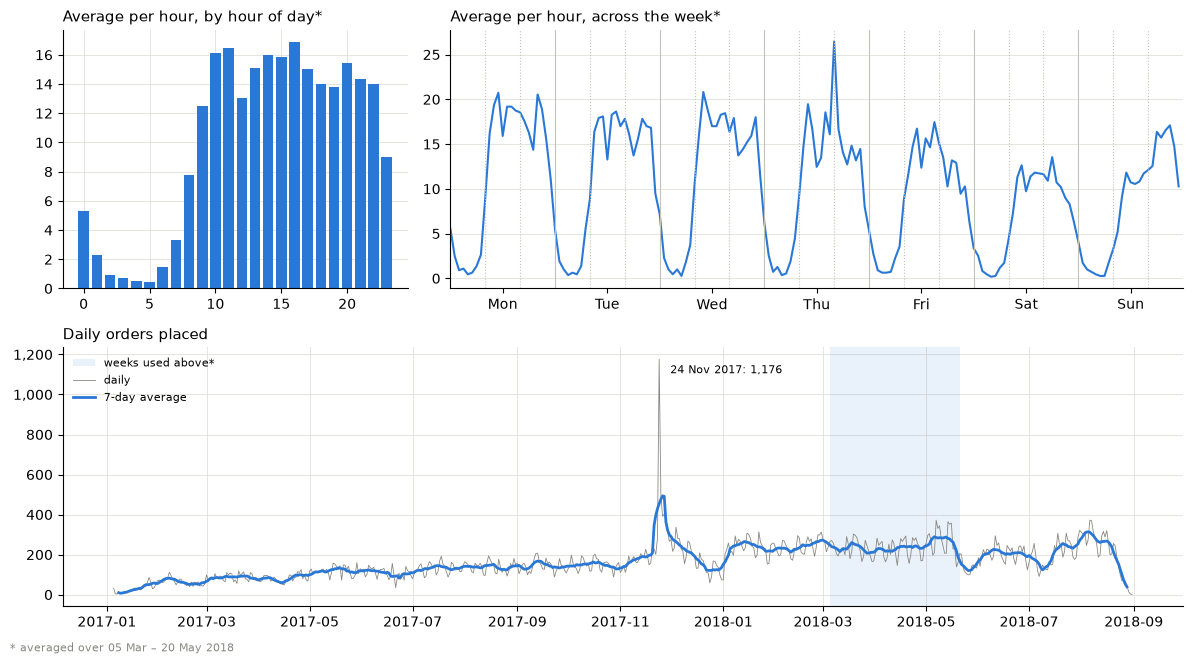

In [33]:
PROFILE_WEEKS = (datetime(2018, 3, 5), datetime(2018, 5, 21))   # 11 full weeks, Mon–Sun: after the holiday season, before the truckers' strike

def plot_seasonality(ts, what):
    "Hour-of-day and hour-of-week averages over PROFILE_WEEKS, plus the daily series over the whole period."
    ts = ts.drop_nulls()
    counts = ts.dt.truncate("1h").to_frame("hour").group_by("hour").agg(n=pl.len())
    # every hour in the period, with zeros, so that averages count the quiet hours too
    hours = (pl.datetime_range(ts.dt.truncate("1d").min(), ts.dt.truncate("1d").max() + timedelta(hours=23), "1h", eager=True)
             .to_frame("hour").join(counts, on="hour", how="left").fill_null(0))
    profile = hours.filter(pl.col("hour").is_between(*PROFILE_WEEKS, closed="left"))
    by_hour = profile.group_by(h=pl.col("hour").dt.hour()).agg(pl.mean("n")).sort("h")
    by_week_hour = profile.group_by(wh=(pl.col("hour").dt.weekday().cast(pl.Int32) - 1) * 24 + pl.col("hour").dt.hour()).agg(pl.mean("n")).sort("wh")   # 0 = Monday 00:00; cast: Int8 weekday × 24 overflows
    daily = (hours.group_by(date=pl.col("hour").dt.date()).agg(pl.sum("n")).sort("date")
             .with_columns(avg_7d=pl.col("n").rolling_mean(7, center=True)))

    fig, ax = plt.subplot_mosaic("ABB;CCC", figsize=(12, 6.5))
    ax["A"].bar(by_hour["h"], by_hour["n"], color=BLUE); ax["A"].set_title("Average per hour, by hour of day*", loc="left", fontsize=11)
    ax["B"].plot(by_week_hour["wh"], by_week_hour["n"], color=BLUE, lw=1.5)
    ax["B"].set_xticks(range(12, 168, 24), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]); ax["B"].set_xlim(0, 168)
    for h in range(8, 168, 8):   # solid line at midnight, faint dots at 8 am and 4 pm
        ax["B"].axvline(h, color="#c3c2b7", lw=.8, ls="-" if h % 24 == 0 else ":")
    ax["B"].grid(axis="x", visible=False); ax["B"].set_title("Average per hour, across the week*", loc="left", fontsize=11)
    ax["C"].axvspan(*PROFILE_WEEKS, color=BLUE, alpha=.1, lw=0, label="weeks used above*")
    ax["C"].plot(daily["date"], daily["n"], color=GREY, lw=.6, label="daily")
    ax["C"].plot(daily["date"], daily["avg_7d"], color=BLUE, lw=2, label="7-day average")
    peak = daily.sort("n").row(-1, named=True)
    ax["C"].annotate(f"{peak['date']:%d %b %Y}: {peak['n']:,}", (peak["date"], peak["n"]), xytext=(8, -4),
                     textcoords="offset points", fontsize=8, va="top")
    ax["C"].legend(frameon=False, fontsize=8, loc="upper left"); ax["C"].set_title(f"Daily {what}", loc="left", fontsize=11)
    for a in ax.values(): a.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
    fig.text(.01, -.01, f"* averaged over {PROFILE_WEEKS[0]:%d %b} – {PROFILE_WEEKS[1] - timedelta(days=1):%d %b %Y}", fontsize=8, color=GREY)
    plt.tight_layout()

plot_seasonality(df_orders["order_purchase_timestamp"], "orders placed")

- **Hour of day:** almost no orders between 2 and 7 am, then a plateau of 13–17 orders an hour from 10 am to 10 pm (spring 2018).
- **Across the week:** every day has the same shape. Weekdays run at about 15–20 orders an hour, and Saturday is lower at about 11. Sunday picks up in the evening, which makes it the busiest weekend slot.
- **Daily series:**
  - Orders grew through 2017 and have been flat at about 230 a day since January 2018.
  - Black Friday (24 Nov 2017) reached 1,176 orders in one day, followed by the usual Christmas and New Year dip.
  - The dip in late May 2018 coincides with the Brazilian truck drivers' strike (21–31 May 2018). It's worth checking when we look at late orders.
  - The fall at the end of August 2018 is where the extract ends, not a real drop.

#### Deliveries follow the carriers' working calendar

The same four panels for `order_delivered_customer_date`, the moment the order is recorded as delivered to the customer. Only delivered orders have it. The orders are still those placed Jan 2017 – Aug 2018, so deliveries run on into September 2018.

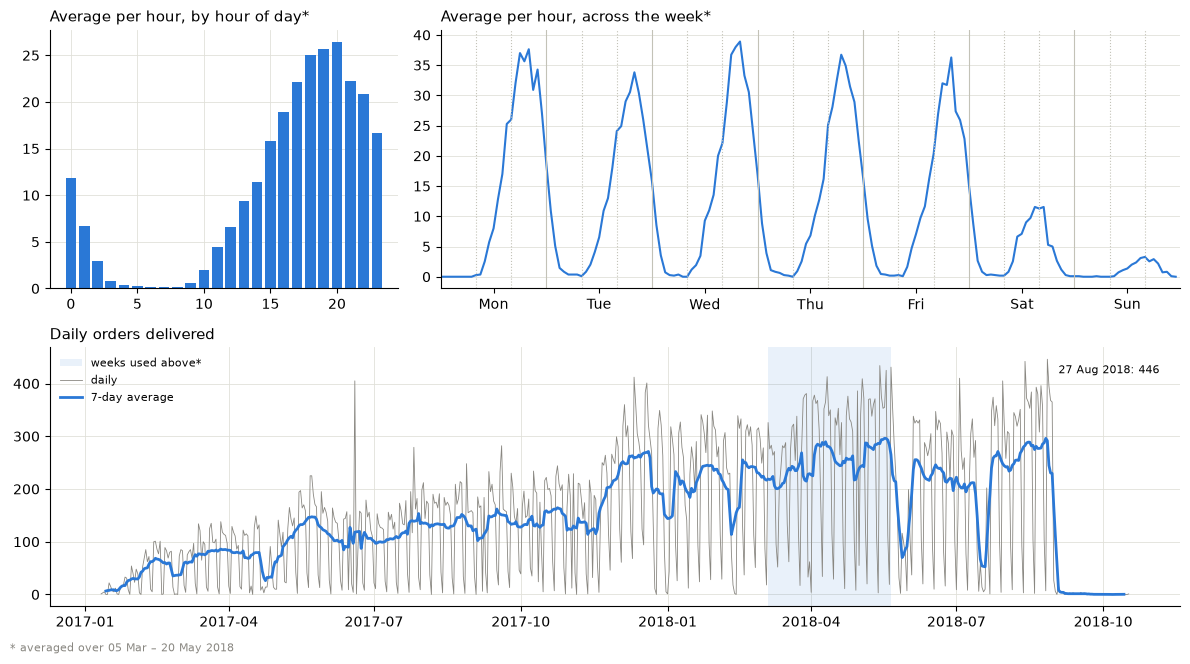

In [34]:
plot_seasonality(df_orders["order_delivered_customer_date"], "orders delivered")

Deliveries follow the carriers' working calendar, not the shoppers':

- **Hour of day:** deliveries build through the afternoon and peak at 6–9 pm, at about 25 an hour (spring 2018). The small bump just after midnight is probably delivery records entered in batches.
- **Across the week:** one peak every weekday afternoon. Weekday peaks reach 34–39 an hour. Saturday has a small midday peak of about 12, and Sunday has almost nothing. Mon–Fri average 200–220 deliveries a day, Saturday 65 and Sunday 14.
- **Daily dips:** near-zero weekdays fall on public holidays:
  - Carnival (27–28 Feb 2017, 12–13 Feb 2018) and Good Friday (14 Apr 2017, 30 Mar 2018)
  - 21 Apr, 1 May, Corpus Christi (15 Jun 2017), 7 Sep, 12 Oct, 2 Nov and 15 Nov
  - Christmas and New Year
- **Two disruptions:**
  - **Truck drivers' strike:** in the week of 28 May 2018, only 634 orders were delivered against about 1,900 in a normal week.
  - **Unexplained:** in the week of 16 July 2018, only 367 were delivered (16–19 July almost none). I don't know of an event that explains it. It may be a recording gap.

  Both should show up as late orders.
- **No single-day spike:** there's no Black Friday spike on the delivery side. That demand spreads over the following weeks, and the busiest delivery days are only about 450.

### Data quality

#### No join loses or duplicates rows

For each join, the table shows:
- `null_keys`: rows of the left table whose key is missing.
- `no_match`: left rows whose key isn't found on the right. An inner join silently drops these; a left join keeps them with empty columns.
- `right_key_unique`: whether the right table's key is unique. If it isn't, the join duplicates rows.

In [35]:
def check_join(name, left, right, on, how):
    "Missing keys, unmatched left rows and right-key uniqueness for joining `left` to `right` on `on`."
    return dict(join=name, how=how, left_rows=left.height, null_keys=left[on].null_count(),
                no_match=left.join(right, on=on, how="anti").height, right_key_unique=right[on].drop_nulls().is_unique().all())

pl.DataFrame([
    check_join("order_items → orders in period", tables["otab_order_items"], df_orders_kept, "order_id", "inner"),
    check_join("orders → customers", df_orders_kept, tables["otab_customers"], "customer_id", "inner"),
    check_join("order_items → sellers", tables["otab_order_items"], tables["otab_sellers"], "seller_id", "inner"),
    check_join("order_items → products", tables["otab_order_items"], tables["otab_products"], "product_id", "left"),
    check_join("products → category names", tables["otab_products"], tables["otab_category_translation"], "product_category_name", "left"),
    check_join("orders → order_totals", df_orders_kept, df_order_totals, "order_id", "left"),
    check_join("customers → zip locations", tables["otab_customers"].select(zip_code_prefix="customer_zip_code_prefix"), df_zip_xy, "zip_code_prefix", "left"),
    check_join("sellers → zip locations", tables["otab_sellers"].select(zip_code_prefix="seller_zip_code_prefix"), df_zip_xy, "zip_code_prefix", "left"),
    check_join("orders → order_features", df_orders_kept, df_order_features, "order_id", "left"),
    check_join("orders → payments (boleto)", df_orders_kept, df_boleto, "order_id", "left"),
])

join,how,left_rows,null_keys,no_match,right_key_unique
str,str,i64,i64,i64,bool
"""order_items → orders in period""","""inner""",112650,0,371,true
"""orders → customers""","""inner""",99092,0,0,true
"""order_items → sellers""","""inner""",112650,0,0,true
"""order_items → products""","""left""",112650,0,0,true
"""products → category names""","""left""",32951,610,623,true
"""orders → order_totals""","""left""",99092,0,739,true
"""customers → zip locations""","""left""",99441,0,278,true
"""sellers → zip locations""","""left""",3095,0,7,true
"""orders → order_features""","""left""",99092,0,739,true


In [36]:
order_columns = ["main_seller", "in_state", "weight_kg", "distance_km", "shipping_limit", "boleto", "approval_hours"]
print(f"{df_items.join(tables['otab_products'], on='product_id', how='left')['product_weight_g'].is_null().sum()} items have no product weight · "
      f"{(df_orders['approval_hours'] < 0).sum()} orders approved before purchase")
df_orders.select(order_columns).null_count()   # orders missing each order-feature column

18 items have no product weight · 0 orders approved before purchase


main_seller,in_state,weight_kg,distance_km,shipping_limit,boleto,approval_hours
u32,u32,u32,u32,u32,u32,u32
739,739,739,1228,739,0,135


**What the checks show.** No join loses or duplicates rows by accident:

- **Missing keys:** no join key is ever missing, except product category (610 products have none).
- **Intended filter:** the only rows an inner join drops are the 371 items from orders outside Jan 2017 – Aug 2018, which is the period filter.
- **Orders without items:** 739 kept orders have no items (602 `unavailable`, 132 `canceled`, 5 `created`). They never shipped, so the left join keeps them with empty prices.
- **Untranslated categories:** 13 products have a Portuguese category with no English translation (`pc_gamer` and a kitchen-appliances category). They keep their Portuguese name as `category`. The 610 products with no category get `missing_category`.
- **Locations:** 278 customers and 7 sellers have a zip prefix with no geolocation points. With the 739 orders that have no items, 1,228 orders have no distance.
- **Other missing values:** 18 items have no product weight, so they count as 0 kg. 135 orders were never approved, so they have no hours to approval. Every order in the period has a payment record.
- **Unique keys:** every right-hand key is unique, so no join multiplies rows.

#### Quantity is stored as repeated rows, and one order can have several sellers

In [37]:
print(f"{(df_order_totals['n_items'] > 1).mean():.1%} of orders have more than one item, "
      f"{(df_order_totals['n_sellers'] > 1).mean():.1%} have items from more than one seller")

examples = [df_order_totals.filter((pl.col("n_items") >= 3) & (pl.col("n_sellers") == 1)).sort("order_id")["order_id"][0],   # several items, one seller
            df_order_totals.filter(pl.col("n_sellers") > 1).sort("order_id")["order_id"][0]]                                   # several sellers
df_items.filter(pl.col("order_id").is_in(examples)).sort("order_id", "order_item_id").select(
    "order_id", "order_item_id", "seller_id", "seller_state", "category", "price_excl_delivery", "delivery_fee")

9.9% of orders have more than one item, 1.3% have items from more than one seller


order_id,order_item_id,seller_id,seller_state,category,price_excl_delivery,delivery_fee
str,i64,str,str,str,f64,f64
"""00143d0f86d6fbd9f9b38ab440ac16f5""",1,"""a17f621c590ea0fab3d5d883e1630ec6""","""SP""","""sports_leisure""",21.33,15.1
"""00143d0f86d6fbd9f9b38ab440ac16f5""",2,"""a17f621c590ea0fab3d5d883e1630ec6""","""SP""","""sports_leisure""",21.33,15.1
"""00143d0f86d6fbd9f9b38ab440ac16f5""",3,"""a17f621c590ea0fab3d5d883e1630ec6""","""SP""","""sports_leisure""",21.33,15.1
"""002f98c0f7efd42638ed6100ca699b42""",1,"""7299e27ed73d2ad986de7f7c77d919fa""","""MG""","""consoles_games""",8.99,32.57
"""002f98c0f7efd42638ed6100ca699b42""",2,"""fa40cc5b934574b62717c68f3d678b6d""","""SP""","""toys""",44.9,7.16


The same two orders in `df_orders`, with their items added up:

In [38]:
df_orders.filter(pl.col("order_id").is_in(examples)).select(
    "order_id", "order_status", "n_items", "n_sellers", "price_excl_delivery", "delivery_fee", "price_incl_delivery")

order_id,order_status,n_items,n_sellers,price_excl_delivery,delivery_fee,price_incl_delivery
str,str,u32,u32,f64,f64,f64
"""00143d0f86d6fbd9f9b38ab440ac16f5""","""delivered""",3,1,63.99,45.3,109.29
"""002f98c0f7efd42638ed6100ca699b42""","""delivered""",2,2,53.89,39.73,93.62


- **Quantity is stored as repeated rows.** In the first order, the same product appears three times, each row with its own price and delivery fee. 6,968 orders contain a product more than once.
- **Several sellers can share one order.** The second order has two sellers in different states. The data still records it as one order, with one promised date and one delivery date.

#### Several-seller orders record only the first parcel's delivery

An order has a single delivery date, even when several sellers ship it in separate parcels. Delivered orders are split by how many sellers and items they have, and compared on recorded lateness, review score, and how often the review comment says something was missing (Portuguese keywords such as *faltou*, *não recebi*, *apenas um*).

In [39]:
MISSING = "faltou|falta|faltando|apenas um|só um|so um|somente um|não recebi|nao recebi|outro produto|segundo produto|metade|incompleto|um dos produtos|um dos itens"
df_reviews = tables["otab_order_reviews"].group_by("order_id").agg(
    score=pl.mean("review_score"), comment=pl.col("review_comment_message").drop_nulls().str.to_lowercase().str.join(" "))
basket = (pl.when(pl.col("n_sellers") > 1).then(pl.lit("several sellers"))
          .when(pl.col("n_items") > 1).then(pl.lit("one seller, several items")).otherwise(pl.lit("one seller, one item")))
df_basket = (df_delivered.join(df_reviews, on="order_id", how="left")
    .with_columns(basket=basket, missing=pl.col("comment").str.contains(MISSING)))
with pl.Config(tbl_cols=-1, float_precision=3):
    display(df_basket.group_by("basket").agg(
    orders=pl.len(), late=pl.mean("late"), promised_days=pl.median("promised_days"),
    days_to_deliver=((pl.col("order_delivered_customer_date") - pl.col("order_purchase_timestamp")).dt.total_hours() / 24).median(),
    score=pl.mean("score"), one_star=(pl.col("score") <= 1).mean(), mentions_missing=pl.mean("missing"),
    low_score_on_time_missing=pl.col("missing").filter(~pl.col("late"), pl.col("score") <= 2).mean()).sort("orders", descending=True))

basket,orders,late,promised_days,days_to_deliver,score,one_star,mentions_missing,low_score_on_time_missing
str,u32,f64,f64,f64,f64,f64,f64,f64
"""one seller, one item""",86598,0.070,23.167,10.250,4.214,0.084,0.023,0.098
"""one seller, several items""",8333,0.060,23.125,10.125,3.755,0.189,0.093,0.321
"""several sellers""",1272,0.010,24.438,7.917,2.855,0.356,0.267,0.451


In [40]:
multi = df_basket.filter(pl.col("basket") == "several sellers")
rest_rate = df_basket.filter(pl.col("basket") != "several sellers")["late"].mean()
hidden = multi.filter(~pl.col("late"), pl.col("score") <= 2, pl.col("missing")).height
n, n_late = df_delivered.height, df_delivered["late"].sum()
print(f"{multi.height:,} several-seller orders ({multi.height / n:.1%} of delivered): recorded late {multi['late'].mean():.1%}, against {rest_rate:.1%} for other orders")
print(f"{hidden} more are recorded on time but rated 1–2 stars with a comment about something missing ({hidden / multi.height:.0%} of several-seller orders)")
for name, extra in [("at the other orders' late rate", multi.height * rest_rate - multi["late"].sum()), ("counting those complaints as late", hidden)]:
    print(f"Delivered late rate {name}: {n_late / n:.2%} → {(n_late + extra) / n:.2%}")

1,272 several-seller orders (1.3% of delivered): recorded late 1.0%, against 6.9% for other orders
264 more are recorded on time but rated 1–2 stars with a comment about something missing (21% of several-seller orders)
Delivered late rate at the other orders' late rate: 6.79% → 6.87%
Delivered late rate counting those complaints as late: 6.79% → 7.06%


- **Several-seller orders look fast and punctual on paper:** 1.0% late against 6.9% for other orders, and delivered in a median 7.9 days against about 10, despite slightly longer promises.
- **Customers say otherwise.** They average 2.9 stars against 4.2 for single-item orders, 36% give one star, and 27% of them complain that something was missing. Among those recorded on time but rated 1–2 stars, 45% say so.
- **So the delivery date is most likely the first parcel's arrival, not the last.** Their lateness is understated.
- **Size of the problem: small for the headline, large for these orders.** They are 1.3% of delivered orders. At other orders' late rate they would add about 74 late orders, and counting the 264 on-time-but-complaining orders as late would add 264. Either way the delivered late rate moves by less than 0.3 points (6.8% → 6.9–7.1%), but for these orders the true late rate is probably closer to 20% than 1%.
- Orders from one seller with several items show the same pattern on a smaller scale (9% mention something missing), probably because some ship in more than one parcel.

#### A few hundred timestamps contradict each other

Timestamps that contradict each other or the order status.

In [41]:
checks = {
    "status delivered, no delivery date": (pl.col("order_status") == "delivered") & pl.col("order_delivered_customer_date").is_null(),
    "delivery date, status not delivered": (pl.col("order_status") != "delivered") & pl.col("order_delivered_customer_date").is_not_null(),
    "handed to carrier before purchase": pl.col("order_delivered_carrier_date") < pl.col("order_purchase_timestamp"),
    "handed to carrier before approval": pl.col("order_delivered_carrier_date") < pl.col("order_approved_at"),
    "delivered before handed to carrier": pl.col("order_delivered_customer_date") < pl.col("order_delivered_carrier_date"),
    "delivered before purchase": pl.col("order_delivered_customer_date") < pl.col("order_purchase_timestamp")}
pl.DataFrame({"check": list(checks), "orders": [df_orders.select(e.sum()).item() for e in checks.values()]}).with_columns(
    share=pl.col("orders") / df_orders.height)

check,orders,share
str,i64,f64
"""status delivered, no delivery date""",8,0.000081
"""delivery date, status not delivered""",1,0.00001
"""handed to carrier before purchase""",166,0.001675
"""handed to carrier before approval""",1359,0.013715
"""delivered before handed to carrier""",19,0.000192
"""delivered before purchase""",0,0.0


- **Status and dates mostly agree.** 8 orders marked delivered have no delivery date, and 1 order has a delivery date under another status. §3 requires both, so these 9 are counted as not delivered.
- **Some timestamps are impossible.** 166 orders (0.2%) were handed to the carrier before they were placed, and 19 were delivered before they were handed over. These are clock or data-entry errors; they could misassign a few orders between seller and carrier, which doesn't change the 72/28 split.
- **1,359 orders (1.4%) were handed to the carrier before payment approval.** Either sellers shipped before payment cleared, or the approval time was recorded late. Either way, hours to approval is noisy for these orders.
- **Noted elsewhere:**
  - 278 customers and 7 sellers have a zip prefix with no location, so 1,228 orders have no distance (§1).
  - 610 products have no category and 18 no weight (§1).
  - Almost no deliveries were recorded on 16–19 July 2018, which may be a recording gap (§2).
  - A small bump of deliveries just after midnight probably reflects records entered in batches (§2).